# Feature Engineering Lab — see every claim from the README with your own eyes

This notebook is the hands-on companion to [`../README.md`](../README.md). It works through one messy, realistic
table (customers of a subscription service; target: did they **churn**, i.e. leave?) and fixes it one step at a time.
Every lab has a short goal, the code, the numbers/plots, and a **"How to read this"** box.

**How to use it**

1. Run the first code cell (imports). After that, run the labs in order (`Shift + Enter` cell by cell, or
   **Run All**). Labs reuse tables made in earlier labs, so top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output: try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

**One rule used everywhere:** the test rows are split off in Lab 1 and not touched again until Lab 20.
Every "before vs after" score in between is a **5-fold cross-validated ROC-AUC on the training rows**
(Lab 20 and README section 21 explain why). ROC-AUC = the chance that a random churner gets a higher churn score
than a random non-churner: **0.5 is a coin flip, 1.0 is perfect.**

| Part | Labs | Steps from the README |
|---|---|---|
| **[A. Hygiene before anything else](#part-a)** | [0](#lab-0) · [1](#lab-1) · [2](#lab-2) · [3](#lab-3) · [4](#lab-4) · [5](#lab-5) | meet the data, split first, column types, useless columns, leakage, data types |
| **[B. Cleaning values](#part-b)** | [6](#lab-6) · [7](#lab-7) · [8](#lab-8) · [9](#lab-9) | missing values, outliers, skew, scaling |
| **[C. Categories and dates](#part-c)** | [10](#lab-10) · [11](#lab-11) · [12](#lab-12) | encoding, rare categories, date features |
| **[D. Creating features](#part-d)** | [13](#lab-13) · [14](#lab-14) · [15](#lab-15) | domain features, interactions, binning |
| **[E. Fewer, better features](#part-e)** | [16](#lab-16) · [17](#lab-17) · [18](#lab-18) · [19](#lab-19) | correlated columns, feature selection, dimensionality reduction, feature importance, SHAP |
| **[F. Putting it together](#part-f)** | [20](#lab-20) | the pipeline scripts: validate every step by cross-validation |
| **[Summary](#summary)** | all | what each lab showed, in one table |

Everything runs offline: the table is in [`../data/customer_churn.csv`](../data/customer_churn.csv) (made by
[`../data/make_customer_churn.py`](../data/make_customer_churn.py)) and the toy datasets ship inside scikit-learn.

In [1]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import shap

from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import RFE, SelectFromModel, SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder, PolynomialFeatures, PowerTransformer, RobustScaler,
                                   StandardScaler, TargetEncoder)
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
DATA_FILE = Path("../data/customer_churn.csv")
SCRIPTS_DIR = Path("../scripts")
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # the same 5 folds in every lab


def cv_auc(model, X, y):
    """Mean ROC-AUC of `model` over the 5 cross-validation folds of (X, y)."""
    return cross_val_score(model, X, y, cv=CV, scoring="roc_auc").mean()


def linear_model(*first_steps):
    """Fill gaps with the median, standardise, logistic regression. Optional extra steps (e.g. an encoder) go first.
    Wrapped in a pipeline, so every step is re-fitted on the training folds only."""
    return make_pipeline(*first_steps, SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(max_iter=5000))


def tree_model():
    """Gradient-boosted trees: the 'tree model' used in most labs. Handles gaps by itself."""
    return HistGradientBoostingClassifier(random_state=SEED)

/private/tmp/claude-501/-Users-aprabhak--claude-spares-spare-IyMPYx/8a76e0ac-39df-4ddb-ae26-3519f1637331/scratchpad/fe-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
<a id="part-a"></a>
# Part A — Hygiene before anything else

<a id="lab-0"></a>
## Lab 0 · Meet the data

**Goal:** look at the raw table before doing anything to it: its size, a few rows, and the target.

In [2]:
df = pd.read_csv(DATA_FILE)
print(f"{df.shape[0]} rows x {df.shape[1]} columns")
print("churn share:", df["churned"].mean())
df.head(3).T

3000 rows x 35 columns
churn share: 0.5


,0,1,2
customer_id,CUST-101565,CUST-101488,CUST-100642
signup_date,2023-05-21,2023-03-13,2021-12-13
age,44.0,50.0,43.0
monthly_income,8390.0,NaN,3050.0
plan,premium,standard,standard
monthly_charges,101.18,$62.96,$49.44
total_spend,1875.91,1243.9,1813.67
num_support_calls,4,7,2
weekly_logins,7,9,4
monthly_logins,30,38,18


<details>
<summary><b>How this table was made: the hidden truth (click to expand)</b></summary>

In real work you never know why customers churn. Here the data was generated, so we *do* know, and every lab can
check whether a step uncovers a real effect or not. The churn score is a sum of these effects (plus random noise; the
top half of scores are churners, so the classes are exactly 50 / 50):

| Real effect | Which step can uncover it |
|---|---|
| unhappy customers leave (measured by 8 noisy survey questions) | dimensionality reduction (Lab 18) |
| customers who stop using the service leave (logins, session minutes, days since last login) | date features (Lab 12) |
| new customers leave more (effect grows with the *log* of tenure) | date features, skew (Labs 8, 12) |
| December / January promo sign-ups leave more | cyclical month (Lab 12) |
| young and old customers leave more (a U shape in age) | polynomials, binning (Labs 14, 15) |
| customers paying a large share of their income leave | ratio feature (Lab 13) |
| premium customers with many support calls leave (an interaction) | interactions (Lab 14) |
| customers paying by mailed check leave more | fixing spellings + encoding (Labs 5, 10) |
| each city has its own churn level (120 cities) | target encoding, rare categories (Labs 10, 11) |

And the mess added on top: an ID column, a constant column, a duplicate column, money stored as text (`"$49.44"`),
dates stored as text, 13 spellings of 4 payment methods, impossible ages (0, 199, 999), missing values (income is
missing more often for churners), 15 automated accounts with 40–80 support calls, five pure-noise "vendor score"
columns, and one leaky column (`retention_call_made`: a call made *after* a customer asks to cancel).
</details>

> **How to read this**
> * 3,000 customers, 35 columns, churn share exactly **0.5**: a balanced binary target, the easiest case.
> * Already in three rows you can see trouble: `monthly_charges` is text (`"$49.44"` vs `"101.18"`), dates are text,
>   `payment_method` is spelled differently in different rows, `country` looks constant and `monthly_fee` looks like
>   a copy of `monthly_charges`.

<a id="lab-1"></a>
## Lab 1 · Split first (stratified hold-out)

**Goal:** lock away a test part *before* looking closely at the data or fitting anything, and see what
**stratified** splitting buys you. Stratified = each part keeps the same share of each class as the whole table.

train: 2400 rows, churn share 0.500
test : 600 rows, churn share 0.500

the 200-row sample itself has churn share 0.485


random split     : test churn share ranges from 0.300 to 0.700
stratified split : test churn share ranges from 0.475 to 0.475


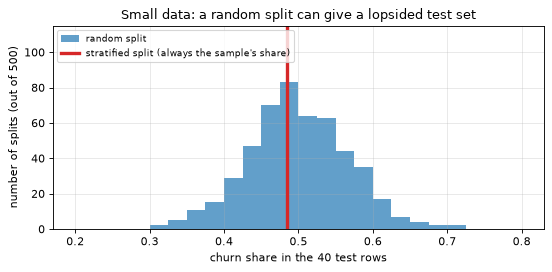

In [3]:
train, test = train_test_split(df, test_size=0.2, stratify=df["churned"], random_state=SEED)  # <- try test_size
print(f"train: {len(train)} rows, churn share {train['churned'].mean():.3f}")
print(f"test : {len(test)} rows, churn share {test['churned'].mean():.3f}")

# Why stratify? Split a SMALL sample (200 rows) 500 times and look at the churn share of the 40 test rows.
small = df.sample(200, random_state=SEED)
print(f"\nthe 200-row sample itself has churn share {small['churned'].mean():.3f}")
shares = {"random split": [], "stratified split": []}
for seed in range(500):
    _, part = train_test_split(small, test_size=0.2, random_state=seed)
    shares["random split"].append(part["churned"].mean())
    _, part = train_test_split(small, test_size=0.2, random_state=seed, stratify=small["churned"])
    shares["stratified split"].append(part["churned"].mean())
for name, values in shares.items():
    print(f"{name:17s}: test churn share ranges from {min(values):.3f} to {max(values):.3f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(shares["random split"], bins=np.arange(0.2, 0.81, 0.025), alpha=0.7, label="random split")
ax.axvline(small["churned"].mean(), color="tab:red", lw=3, label="stratified split (always the sample's share)")
ax.set_xlabel("churn share in the 40 test rows"); ax.set_ylabel("number of splits (out of 500)")
ax.set_ylim(0, 115); ax.set_title("Small data: a random split can give a lopsided test set")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * Train has 2,400 rows, test 600; both have churn share **0.500**. From now on, `test` is not touched until Lab 20.
> * With only 200 rows (churn share 0.485), a random split gives test parts with anywhere from **0.300 to 0.700**
>   churners — a lopsided test set gives a misleading score. The stratified split gives **0.475 every time** (19 of
>   40 rows): the sample's own share, as close as 40 rows allow.
> * Why split *first*: every later step learns something from data (a median, a category's churn rate, which
>   columns to keep). If it learns it from rows that end up in the test part, the test score is no longer a fair
>   preview of new data. Labs 10 and 17 show how big that error can get.

<a id="lab-2"></a>
## Lab 2 · Understand column types

**Goal:** sort every column into a *kind* (number, number stored as text, date, category, ID, free text, ...),
because the kind decides which later steps apply. The rules below are simple guesses; you confirm them by eye.

In [4]:
def guess_kind(column):
    """A first guess at what a column holds, from its values only."""
    values = column.dropna()
    n_unique = values.nunique()
    if n_unique <= 1:
        return "constant"
    if pd.api.types.is_numeric_dtype(column):
        return "number: few values (count/code)" if n_unique <= 10 else "number: continuous"
    if pd.to_numeric(values.str.replace(r"[$,]", "", regex=True), errors="coerce").notna().all():
        return "NUMBER STORED AS TEXT"
    if pd.to_datetime(values, errors="coerce", format="%Y-%m-%d").notna().all():
        return "DATE STORED AS TEXT"
    if n_unique / len(values) > 0.95:
        return "ID (different on every row)"
    if n_unique == 2:
        return "yes/no stored as text"
    if values.str.split().str.len().mean() >= 2.5:
        return "free text"
    return "category: many levels" if n_unique > 20 else "category: few levels"


column_report = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "kind (guess)": [guess_kind(train[c]) for c in train.columns],
    "distinct": train.nunique(),
    "missing %": (100 * train.isna().mean()).round(1),
    "example": [train[c].dropna().iloc[0] for c in train.columns],
})
column_report

,dtype,kind (guess),distinct,missing %,example
customer_id,str,ID (different on every row),2400,0.0,CUST-100570
signup_date,str,DATE STORED AS TEXT,1327,0.0,2024-10-13
age,float64,number: continuous,71,6.9,42.0
monthly_income,float64,number: continuous,787,16.3,6300.0
plan,str,category: few levels,3,0.0,premium
monthly_charges,str,NUMBER STORED AS TEXT,2153,0.0,$104.79
total_spend,float64,number: continuous,2391,0.0,277.39
num_support_calls,int64,number: continuous,28,0.0,2
weekly_logins,int64,number: continuous,19,0.0,4
monthly_logins,int64,number: continuous,67,0.0,17


> **How to read this**
> * **Numbers stored as text**: `monthly_charges` and `monthly_fee` (the `$` sign makes pandas read them as text) —
>   fixed in Lab 5. **Dates stored as text**: `signup_date`, `last_login_date` — turned into features in Lab 12.
> * **ID**: `customer_id` (2,400 distinct values in 2,400 rows). **Constant**: `country`. Both dropped in Lab 3.
> * **yes/no as text**: `is_senior` and `retention_call_made` (the leak, Lab 4).
> * **Categories**: `plan`, `region`, `device` have few levels; `payment_method` *looks* like it has 13 levels but
>   really has 4 (Lab 5); `city` has many levels (Labs 10–11). `support_note` is short **free text** (Lab 13).
> * **Missing values** in `age`, `monthly_income`, `device` and `support_note` (Lab 6).
> * The guesses are a starting point, not the truth: `num_support_calls` is labelled "continuous" but it is a count,
>   and `survey_q*` are 1–5 answers, labelled "few values". Always check by eye.

<a id="lab-3"></a>
## Lab 3 · Drop useless columns (IDs, constants, duplicates)

**Goal:** find columns that cannot carry information, and see what happens if an ID is left in.

In [5]:
print("customer_id :", train["customer_id"].nunique(), "distinct values in", len(train), "rows")
print("country     :", train["country"].unique().tolist())
print("monthly_fee is an exact copy of monthly_charges:", train["monthly_fee"].equals(train["monthly_charges"]))

# What if the ID stays in? Give a decision tree ONLY the number inside the ID.
id_number = train["customer_id"].str.replace("CUST-", "").astype(int).to_frame()
memoriser = DecisionTreeClassifier(random_state=SEED).fit(id_number, train["churned"])
print(f"\ntree on the ID number: accuracy on its own training rows = {memoriser.score(id_number, train['churned']):.3f}")
print(f"                      cross-validated ROC-AUC           = "
      f"{cv_auc(DecisionTreeClassifier(random_state=SEED), id_number, train['churned']):.3f}")

customer_id : 2400 distinct values in 2400 rows
country     : ['US']
monthly_fee is an exact copy of monthly_charges: True

tree on the ID number: accuracy on its own training rows = 1.000
                      cross-validated ROC-AUC           = 0.518


> **How to read this**
> * The ID has a different value on every row, `country` has one value (`US`), and `monthly_fee` repeats
>   `monthly_charges` exactly. None of them can help.
> * Worse, the ID can **fool you**: a tree on the ID number alone scores **1.000** on its training rows — it simply
>   memorised which ID churned — and **0.518** (a coin flip) on rows it hasn't seen.
> * **When an ID is not useless:** if IDs were handed out in order, a bigger ID means a newer customer, which is a
>   real (time) signal. Then extract that signal on purpose (e.g. sign-up date) instead of keeping the raw ID.

<a id="lab-4"></a>
## Lab 4 · Remove leakage

**Goal:** catch a column that gives away the answer. Leakage = information that would not be available at the
moment you make the prediction (here: a retention call happens *after* the customer asked to cancel).
The tell-tale sign is a single column that predicts **too** well.

In [6]:
def single_column_auc(values, y):
    """ROC-AUC of one column used alone (text: each category's churn rate; only for columns with few categories)."""
    if not pd.api.types.is_numeric_dtype(values):
        values = values.map(y.groupby(values).mean())
    values = values.fillna(values.median())
    auc = roc_auc_score(y, values)
    return max(auc, 1 - auc)          # a column can also predict "the other way round"


few_levels = [c for c in train.columns if c != "churned"
              and (pd.api.types.is_numeric_dtype(train[c]) or train[c].nunique() <= 20)]
scan = pd.Series({c: single_column_auc(train[c], train["churned"]) for c in few_levels}).sort_values(ascending=False)
print("best single columns (ROC-AUC on their own):")
print(scan.head(6).round(3).to_string())

numbers_now = train.select_dtypes("number").drop(columns="churned")
with_leak = numbers_now.assign(retention_call_made=(train["retention_call_made"] == "yes").astype(int))
print(f"\nlogistic regression, numeric columns          : CV ROC-AUC {cv_auc(linear_model(), numbers_now, train['churned']):.3f}")
print(f"logistic regression, + retention_call_made     : CV ROC-AUC {cv_auc(linear_model(), with_leak, train['churned']):.3f}")

best single columns (ROC-AUC on their own):
retention_call_made    0.936
support_note           0.643
num_support_calls      0.626
survey_q6              0.626
survey_q8              0.624
survey_q2              0.617

logistic regression, numeric columns          : CV ROC-AUC 0.702
logistic regression, + retention_call_made     : CV ROC-AUC 0.960


> **How to read this**
> * On its own, `retention_call_made` scores **0.936**. The next best column scores **0.643**. One column being
>   that much better than everything else is the classic smell of leakage.
> * Adding it lifts the model from **0.702** to **0.960**. That number is a lie: at prediction time (*will this
>   customer leave next month?*) nobody has made the retention call yet.
> * The test for every suspicious column: *"Would I know this value at the moment I need the prediction?"* If not,
>   drop it. Typical leaks: IDs or timestamps assigned after the outcome, totals that include the future, a
>   "status" column, or anything computed using the target.

<a id="lab-5"></a>
## Lab 5 · Fix data types

**Goal:** turn text that is really a number into a number, yes/no into 1/0, dates into dates, unify spellings,
and turn impossible values into "missing". Then see what the fixes are worth.

In [7]:
print("payment_method as stored (churn share per spelling):")
print(train.groupby("payment_method")["churned"].agg(["count", "mean"]).round(2).to_string())
print("\nimpossible ages:", train["age"][~train["age"].between(15, 100)].value_counts().to_dict())


def fix_types(frame):
    """Return a copy with types and spellings fixed, and the columns from Labs 3-4 dropped."""
    out = frame.drop(columns=["customer_id", "country", "monthly_fee", "retention_call_made"])   # Labs 3 and 4
    out["monthly_charges"] = pd.to_numeric(out["monthly_charges"].str.replace("$", "", regex=False))
    out["is_senior"] = out["is_senior"].map({"Y": 1, "N": 0})
    for column in ["payment_method", "region", "device", "plan", "city", "support_note"]:
        out[column] = out[column].str.strip().str.lower().str.replace("_", " ")
    for column in ["signup_date", "last_login_date"]:
        out[column] = pd.to_datetime(out[column])
    out["age"] = out["age"].where(out["age"].between(15, 100))       # 0, 199, 999 are typos -> missing
    return out


train_fixed = fix_types(train)
y = train_fixed["churned"]
print("\npayment_method after tidying:")
print(train_fixed.groupby("payment_method")["churned"].agg(["count", "mean"]).round(2).to_string())

before = train.select_dtypes("number").drop(columns="churned")
after = pd.concat([train_fixed.select_dtypes("number").drop(columns="churned"),
                   pd.get_dummies(train_fixed["payment_method"], dtype=int)], axis=1)
print(f"\nCV ROC-AUC, numeric columns as loaded ({before.shape[1]} columns): {cv_auc(linear_model(), before, y):.3f}")
print(f"CV ROC-AUC, after fixing types ({after.shape[1]} columns)    : {cv_auc(linear_model(), after, y):.3f}")

payment_method as stored (churn share per spelling):
                count  mean
payment_method             
 Paypal           204  0.46
 credit card      226  0.49
Bank Transfer     199  0.44
Credit Card       225  0.46
Mailed Check      152  0.66
PayPal            199  0.46
bank transfer     188  0.48
bank_transfer     191  0.54
credit card       199  0.49
credit_card       207  0.47
mailed check      112  0.65
mailed_check      108  0.58
paypal            190  0.47

impossible ages: {199.0: 11, 999.0: 5, 0.0: 3}

payment_method after tidying:
                count  mean
payment_method             
bank transfer     578  0.49
credit card       857  0.48
mailed check      372  0.63
paypal            593  0.46

CV ROC-AUC, numeric columns as loaded (20 columns): 0.702


CV ROC-AUC, after fixing types (26 columns)    : 0.776


> **How to read this**
> * `payment_method` arrived as **13 spellings** of 4 methods ("Mailed Check", "mailed_check", ...). Each spelling
>   holds only a slice of the rows. After tidying (strip spaces, lower-case, `_` → space) there are **4** methods, and
>   "mailed check" clearly stands out with a churn share of **0.63** against 0.46–0.49 for the others.
> * The impossible ages (**0, 199, 999**) are data-entry errors, not real customers. Turning them into *missing* lets
>   Lab 6 handle them honestly instead of treating 999 as a very old customer.
> * Fixing types makes `monthly_charges`, `is_senior` and the payment method usable: CV ROC-AUC goes from **0.702**
>   to **0.776**. Nothing clever has happened yet — this is just letting the model read the data.

---
<a id="part-b"></a>
# Part B — Cleaning values

<a id="lab-6"></a>
## Lab 6 · Missing values: imputation plus "was missing" flags

**Goal:** compare the usual ways of handling gaps — drop the rows, fill with the median, fill *and* add a
"was missing" flag — and see when the flag matters. From here on most labs use the same **base** set of numeric
columns, so the scores are comparable.

share missing, by class:
churned         stayed  churned
age              0.068    0.086
monthly_income   0.064    0.262
device           0.032    0.025
support_note     0.257    0.123



rows kept when dropping rows with gaps: 1859 of 2400

CV ROC-AUC:
  drop rows with gaps            0.753
  fill with median               0.745
  fill with median + flags       0.778
  flag for age only              0.746
  flag for income only           0.778
  trees, gaps left in (native)   0.800
  trees, fill with median        0.798

income std before filling 2895, after median filling 2660


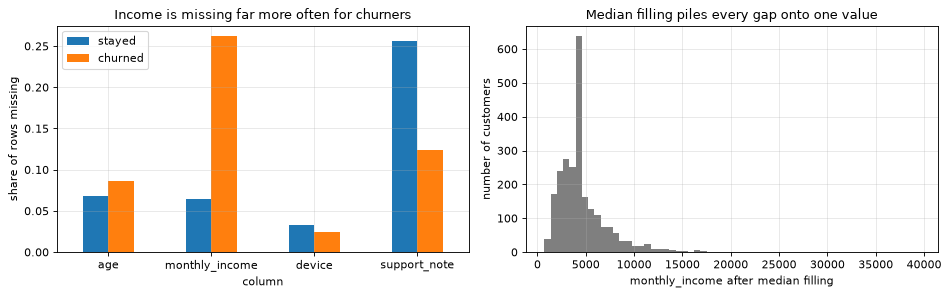

In [8]:
BASE = ["age", "monthly_income", "monthly_charges", "total_spend", "num_support_calls", "weekly_logins",
        "monthly_logins", "avg_session_minutes"] + [f"survey_q{i}" for i in range(1, 9)]
X_base = train_fixed[BASE]

gaps = ["age", "monthly_income", "device", "support_note"]
print("share missing, by class:")
print(train_fixed[gaps].isna().groupby(y).mean().T.rename(columns={0: "stayed", 1: "churned"}).round(3).to_string())

complete_rows = X_base.dropna()
results = {
    "drop rows with gaps": cv_auc(linear_model(), complete_rows, y[complete_rows.index]),
    "fill with median": cv_auc(linear_model(), X_base, y),
    "fill with median + flags": cv_auc(linear_model(SimpleImputer(strategy="median", add_indicator=True)), X_base, y),
    "flag for age only": cv_auc(linear_model(), X_base.assign(age_was_missing=X_base["age"].isna().astype(int)), y),
    "flag for income only": cv_auc(linear_model(),
                                   X_base.assign(income_was_missing=X_base["monthly_income"].isna().astype(int)), y),
    "trees, gaps left in (native)": cv_auc(tree_model(), X_base, y),
    "trees, fill with median": cv_auc(make_pipeline(SimpleImputer(strategy="median"), tree_model()), X_base, y),
}
print(f"\nrows kept when dropping rows with gaps: {len(complete_rows)} of {len(X_base)}")
print("\nCV ROC-AUC:")
for name, auc in results.items():
    print(f"  {name:30s} {auc:.3f}")

income = train_fixed["monthly_income"]
filled = income.fillna(income.median())
print(f"\nincome std before filling {income.std():.0f}, after median filling {filled.std():.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
share = train_fixed[gaps].isna().groupby(y).mean().T
share.plot.bar(ax=axes[0], rot=0, color=["tab:blue", "tab:orange"])
axes[0].legend(["stayed", "churned"]); axes[0].set_xlabel("column"); axes[0].set_ylabel("share of rows missing")
axes[0].set_title("Income is missing far more often for churners")
axes[1].hist(filled, bins=60, color="tab:gray")
axes[1].set_xlabel("monthly_income after median filling"); axes[1].set_ylabel("number of customers")
axes[1].set_title("Median filling piles every gap onto one value")
plt.tight_layout(); plt.show()

> **How to read this**
> * `age` is missing about equally often for both classes (missing *at random*). `monthly_income` is missing for
>   **26.2 %** of churners but only **6.4 %** of those who stayed: here the gap itself is information.
> * Dropping rows throws away **541** of 2,400 customers (keeps 1,859) and scores 0.753 — on a different, smaller
>   set of rows, and useless at prediction time, when a new customer with a gap still needs a prediction.
> * Median filling scores **0.745**. Adding the flags lifts it to **0.778**. The flag for income alone
>   gives the whole gain (**0.778**); the flag for age alone gives nothing (**0.746**) because age is
>   missing at random. **When it doesn't help:** a flag for a column missing at random only adds a useless column.
> * Trees handle gaps natively (**0.800**): `HistGradientBoostingClassifier` sends missing values down
>   whichever branch works best, which captures "income is missing" by itself. Filling first removes that and costs a
>   little (**0.798**).
> * Side effect: filling with one value shrinks the spread (std **2,895** → **2,660**) and creates a spike
>   at the median (right plot). Fine for most models; a problem if you later compute statistics on the column.
> * **Leakage:** the fill value (the median) is learned from data. Inside `linear_model()` the imputer sits in a
>   pipeline, so it is re-learned on the training folds only.

<a id="lab-7"></a>
## Lab 7 · Outliers: detect, then cap (winsorise) or transform

**Goal:** find extreme values with two common rules, cap them, and see which models care.
`num_support_calls` has 15 automated accounts with 40–80 calls among real customers with mostly 0–10.

IQR rule  (above Q3 + 1.5 IQR = 6.0): 108 rows flagged
z-score   (above mean + 3 std = 16.1): 14 rows flagged
99th percentile = 11; values above it: [12, 12, 12, 13, 13, 13, 14, 21, 43, 44, 48, 49, 53, 53, 54, 55, 56, 59, 70, 72, 73]
logistic weight of num_support_calls (raw    data): 0.053
logistic weight of num_support_calls (capped data): 0.214

CV ROC-AUC                       raw     capped


  logistic, base columns      0.745    0.748


  trees,    base columns      0.800    0.803

fraud toy (1.3% frauds), logistic:  raw amounts 0.999   capped at 95th percentile 0.981


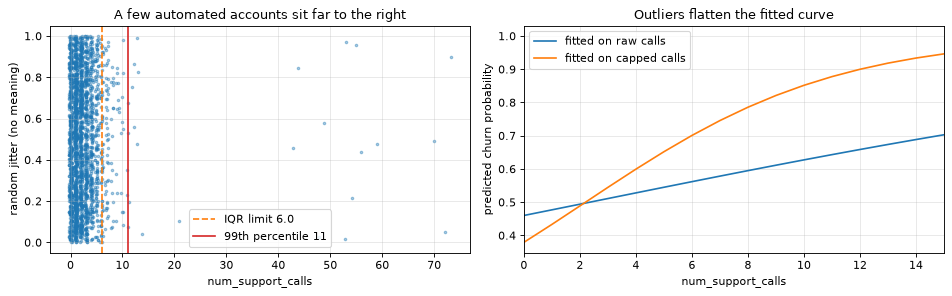

In [9]:
calls = train_fixed["num_support_calls"]
q1, q3 = calls.quantile([0.25, 0.75])
iqr_limit = q3 + 1.5 * (q3 - q1)
z_limit = calls.mean() + 3 * calls.std()
cap_99 = calls.quantile(0.99)
print(f"IQR rule  (above Q3 + 1.5 IQR = {iqr_limit:.1f}): {(calls > iqr_limit).sum()} rows flagged")
print(f"z-score   (above mean + 3 std = {z_limit:.1f}): {(calls > z_limit).sum()} rows flagged")
print(f"99th percentile = {cap_99:.0f}; values above it: {sorted(calls[calls > cap_99].astype(int).tolist())}")


def cap(frame, columns, low_q=0.01, high_q=0.99):        # <- try changing the quantiles
    """Clip each column to its own [low_q, high_q] quantiles (computed on this frame)."""
    out = frame.copy()
    for column in columns:
        out[column] = out[column].clip(*out[column].quantile([low_q, high_q]))
    return out


capped = cap(X_base, BASE)
only_calls = X_base[["num_support_calls"]]
for label, data in [("raw", X_base), ("capped", capped)]:
    weight = linear_model().fit(data, y)[-1].coef_[0][BASE.index("num_support_calls")]
    print(f"logistic weight of num_support_calls ({label:6s} data): {weight:.3f}")
print("\nCV ROC-AUC                       raw     capped")
print(f"  logistic, base columns      {cv_auc(linear_model(), X_base, y):.3f}    {cv_auc(linear_model(), capped, y):.3f}")
print(f"  trees,    base columns      {cv_auc(tree_model(), X_base, y):.3f}    {cv_auc(tree_model(), capped, y):.3f}")

# When capping HURTS: the extremes ARE the signal (fraud risk keeps rising with the size of a payment).
rng = np.random.default_rng(SEED)
amount = pd.DataFrame({"amount": rng.lognormal(3, 1, 4000)})
is_fraud = rng.random(4000) < 1 / (1 + np.exp(-(amount["amount"] - 200) / 20))
print(f"\nfraud toy ({is_fraud.mean():.1%} frauds), logistic:  raw amounts {cv_auc(linear_model(), amount, is_fraud):.3f}   "
      f"capped at 95th percentile {cv_auc(linear_model(), cap(amount, ['amount'], 0, 0.95), is_fraud):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(calls + rng.uniform(-0.3, 0.3, len(calls)), rng.uniform(0, 1, len(calls)), s=5, alpha=0.4)
axes[0].axvline(iqr_limit, color="tab:orange", ls="--", label=f"IQR limit {iqr_limit:.1f}")
axes[0].axvline(cap_99, color="tab:red", label=f"99th percentile {cap_99:.0f}")
axes[0].set_xlabel("num_support_calls"); axes[0].set_ylabel("random jitter (no meaning)"); axes[0].legend()
axes[0].set_title("A few automated accounts sit far to the right")
grid = pd.DataFrame({"num_support_calls": np.arange(0, 81)})
for label, data in [("fitted on raw calls", only_calls), ("fitted on capped calls", cap(only_calls, ["num_support_calls"]))]:
    fitted = linear_model().fit(data, y)
    axes[1].plot(grid, fitted.predict_proba(grid)[:, 1], label=label)
axes[1].set_xlim(0, 15); axes[1].set_xlabel("num_support_calls"); axes[1].set_ylabel("predicted churn probability")
axes[1].set_title("Outliers flatten the fitted curve"); axes[1].legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * The IQR rule flags **108** rows (everything above 6 calls) and the 3-std rule **14**: the two rules disagree,
>   because with a long tail "extreme" is a judgement call. Above the 99th percentile (11 calls) sit a few busy real
>   customers (12–21 calls) and the automated accounts (43–73 calls).
> * The automated accounts churn about half the time, like everyone else, so they drag the fitted curve flat (right
>   plot). Capped, the curve rises more steeply over the real range of 0–10 calls, and the model's weight for calls
>   grows from **0.053** to **0.214**.
> * The score barely moves, though: **0.745 → 0.748** on the base columns. Capping fixes a distorted *shape*; how much
>   that is worth depends on how many outliers there are (here 15 of 3,000 rows).
> * Trees don't care (**0.800** vs **0.803**): a split "calls > 9" puts 12 and 73 on the same side.
> * **When it hurts:** in the fraud toy, risk keeps rising with the size of the payment, so the largest payments are
>   the most suspicious. Capping at the 95th percentile makes the top 5 % identical, and ROC-AUC drops from
>   **0.999** to **0.981** (1.3 % of payments are frauds, nearly all of them inside that top 5 %).
>   First ask *why* a value is extreme: a typo → fix or set missing (Lab 5); a different kind of row (bot) → maybe
>   remove; a genuine rare case → keep, or transform (Lab 8) instead of capping.
> * **Leakage:** the cap limits are learned from data. Here `cap()` uses all 2,400 training rows (a small
>   shortcut); the pipeline scripts learn them inside every fold.

<a id="lab-8"></a>
## Lab 8 · Skewed numerics: log, Box-Cox, Yeo-Johnson

**Goal:** squash long right tails and see who benefits. Skewness measures lopsidedness: 0 = symmetric,
above 1 = a long right tail.

skewness of each column (raw -> log1p):
  monthly_income          2.45 ->  0.09
  num_support_calls      10.06 ->  0.43
  total_spend             1.24 -> -0.83
  avg_session_minutes     1.71 ->  0.10

CV ROC-AUC


  logistic, raw                    0.745
  logistic, log1p on 4 columns     0.759


  logistic, Yeo-Johnson on all     0.751


  trees,    raw                    0.800076


  trees,    log1p on 4 columns     0.800076

toy, skewed x with an accelerating effect:  raw x 0.878   log1p(x) 0.870


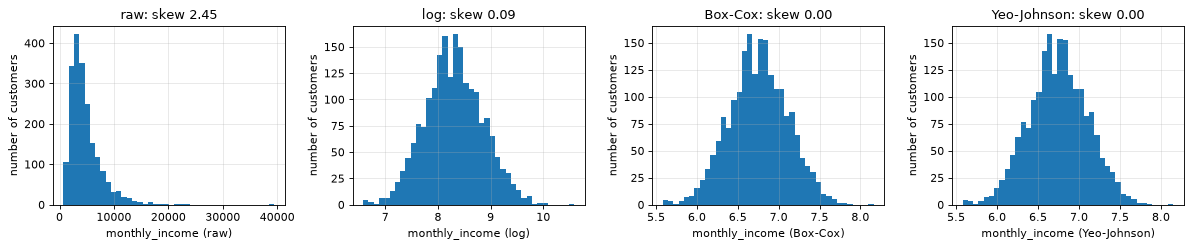

In [10]:
SKEWED = ["monthly_income", "num_support_calls", "total_spend", "avg_session_minutes"]
income = train_fixed["monthly_income"].dropna()
versions = {
    "raw": income,
    "log": np.log(income),
    "Box-Cox": pd.Series(stats.boxcox(income)[0]),
    "Yeo-Johnson": pd.Series(stats.yeojohnson(income)[0]),
}
print("skewness of each column (raw -> log1p):")
for column in SKEWED:
    print(f"  {column:22s} {train_fixed[column].skew():5.2f} -> {np.log1p(train_fixed[column]).skew():5.2f}")

logged = X_base.assign(**{c: np.log1p(X_base[c]) for c in SKEWED})      # log1p(x) = log(1 + x), safe at 0
print("\nCV ROC-AUC")
print(f"  logistic, raw                    {cv_auc(linear_model(), X_base, y):.3f}")
print(f"  logistic, log1p on 4 columns     {cv_auc(linear_model(), logged, y):.3f}")
print(f"  logistic, Yeo-Johnson on all     {cv_auc(linear_model(PowerTransformer()), X_base, y):.3f}")
print(f"  trees,    raw                    {cv_auc(tree_model(), X_base, y):.6f}")
print(f"  trees,    log1p on 4 columns     {cv_auc(tree_model(), logged, y):.6f}")

# When it HURTS: a skewed column whose effect grows FASTER than a straight line (risk accelerates).
rng = np.random.default_rng(SEED)
toy = pd.DataFrame({"x": rng.exponential(1.0, 3000), "other": rng.normal(0, 1, 3000)})
accelerating = (rng.random(3000) < 1 / (1 + np.exp(-(toy["x"] ** 2 - 2 + toy["other"])))).astype(int)
print(f"\ntoy, skewed x with an accelerating effect:  raw x {cv_auc(linear_model(), toy, accelerating):.3f}   "
      f"log1p(x) {cv_auc(linear_model(), toy.assign(x=np.log1p(toy['x'])), accelerating):.3f}")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (name, values) in zip(axes, versions.items()):
    ax.hist(values, bins=40, color="tab:blue")
    ax.set_title(f"{name}: skew {round(values.skew(), 2) + 0.0:.2f}"); ax.set_xlabel(f"monthly_income ({name})")
    ax.set_ylabel("number of customers")
plt.tight_layout(); plt.show()

> **How to read this**
> * Income, calls, spend and session minutes have skew between **1.24** and **10.06** (calls, because of the
>   automated accounts). After log1p, income, calls and session minutes are close to symmetric; `total_spend`
>   overshoots to **−0.83** (now the tail is on the left): log is not always the right strength. The four histograms
>   show log, Box-Cox and Yeo-Johnson all turning the long-tailed income into a bell shape.
> * The linear model gains: **0.745** raw → **0.759** with log1p on the four columns → **0.751** with Yeo-Johnson on
>   every column. Several real effects work on a log-like scale (support calls, tenure), so un-skewing makes them
>   closer to straight lines.
> * Trees: **0.800076** and **0.800076** — identical to six decimals. log is *monotonic* (keeps the order of values),
>   and a tree only cares about order. Don't bother un-skewing for trees.
> * **When it hurts:** a column can be skewed *and* have an effect that grows faster than a straight line. The log
>   bends it the wrong way: the toy drops from **0.878** to **0.870**. Check the score, don't transform by reflex.
> * Box-Cox needs values > 0, log needs ≥ 0 (use log1p), Yeo-Johnson works for any value. **Leakage:** Box-Cox and
>   Yeo-Johnson learn a parameter (λ) from the data, so they belong inside the pipeline (as `PowerTransformer` is here).

<a id="lab-9"></a>
## Lab 9 · Scaling (and why trees don't need it)

**Goal:** see how much the scale of the columns matters for a distance-based model (k-NN), a linear model
(logistic regression) and a tree model, with three common scalers.

     monthly_income  total_spend  survey_q1  num_support_calls
min           720.0        20.92        1.0                0.0
max         39470.0      6791.96        5.0               73.0



CV ROC-AUC by model and scaler:
                         none  standard  min-max  robust
gradient-boosted trees  0.798     0.798    0.798   0.798
k-NN (25 neighbours)    0.617     0.730    0.713   0.745
logistic regression     0.745     0.745    0.744   0.746

convergence warnings (logistic regression did not finish fitting): 5


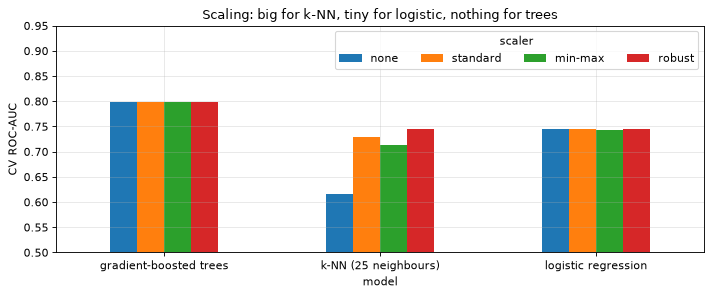

In [11]:
import warnings
from sklearn.exceptions import ConvergenceWarning

print(X_base[["monthly_income", "total_spend", "survey_q1", "num_support_calls"]].describe().loc[["min", "max"]])

scalers = {"none": None, "standard": StandardScaler(), "min-max": MinMaxScaler(), "robust": RobustScaler()}
models = {
    "k-NN (25 neighbours)": KNeighborsClassifier(n_neighbors=25),               # <- try n_neighbors
    "logistic regression": LogisticRegression(max_iter=5000),
    "gradient-boosted trees": tree_model(),
}
table = {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    for model_name, model in models.items():
        for scaler_name, scaler in scalers.items():
            steps = [SimpleImputer(strategy="median")] + ([scaler] if scaler is not None else []) + [model]
            table[(model_name, scaler_name)] = cv_auc(make_pipeline(*steps), X_base, y)
table = pd.Series(table).unstack()[list(scalers)]
print("\nCV ROC-AUC by model and scaler:")
print(table.round(3).to_string())
print(f"\nconvergence warnings (logistic regression did not finish fitting): {len(caught)}")

fig, ax = plt.subplots(figsize=(9, 3.8))
table.plot.bar(ax=ax, rot=0)
ax.set_ylim(0.5, 0.95); ax.set_xlabel("model"); ax.set_ylabel("CV ROC-AUC")
ax.set_title("Scaling: big for k-NN, tiny for logistic, nothing for trees"); ax.legend(title="scaler", ncols=4)
plt.tight_layout(); plt.show()

> **How to read this**
> * Income runs into the thousands while survey answers run from 1 to 5. Unscaled, a difference of 1,000 in income
>   swamps every other column in a distance.
> * **k-NN** (distance-based) jumps from **0.617** to **0.730** with standard scaling and **0.745** with robust
>   scaling. Without scaling, its "nearest neighbours" are simply the customers with the most similar income and spend.
> * **Logistic regression**: **0.745** unscaled and **0.745** scaled. It can adjust its weights to any scale, so the
>   score is the same here, but the solver struggled: **5** convergence warnings (one per fold) without scaling and
>   none with it. With stronger regularisation (small `C`) or many columns, unscaled data also changes the answer,
>   because the penalty then treats columns measured in thousands differently from columns measured in units.
> * **Trees**: identical in every column (**0.798**). A split asks "is income above 4,100?"; scaling changes the
>   number 4,100 but not which customers fall on each side.
> * Min-max is hurt by outliers: the automated accounts (up to 73 calls) squash every real customer into the range
>   0–0.15 of [0, 1], so k-NN scores lower with min-max (**0.713**) than with standard scaling. Robust scaling (median and IQR) ignores them.
> * **Leakage:** a scaler learns means / standard deviations. Fit it on training rows only (inside the pipeline).

---
<a id="part-c"></a>
# Part C — Categories and dates

<a id="lab-10"></a>
## Lab 10 · Categorical encoding: one-hot, ordinal, frequency, target (fitted inside CV)

**Goal:** turn text categories into numbers in different ways and compare. The interesting one is `city`
(119 levels in the training rows). **Target encoding** replaces each city by its churn rate — powerful, and the
easiest way to leak the answer if you compute it carelessly.

<details>
<summary><b>Why naive target encoding leaks, and how cross-fitting fixes it (click to expand)</b></summary>

Naive target encoding: for each city, average the target over **all** training rows of that city, then use that
number as a feature. Take a city with 3 customers, 2 of whom churned: its value is 2/3. Each of those 3 rows now
carries a number that was computed **from its own label**. For a city with a single customer the value *is* the
label (0 or 1). The model learns "a high city value means churn", which is true on these rows only because the
value was built from the answer. On new customers the trick is gone, so the cross-validated score lies.

Two fixes, used together by scikit-learn's `TargetEncoder`:

1. **Cross-fitting.** Split the training rows into k folds. Each row's value is the city's churn rate computed on
   the *other* k−1 folds. No row ever sees its own label.
2. **Shrinkage (smoothing).** A city's rate is pulled toward the overall rate, the more so the fewer rows it has:
   $\text{value} = \dfrac{n_{\text{city}} \cdot \text{rate}_{\text{city}} + m \cdot \text{rate}_{\text{all}}}{n_{\text{city}} + m}$.
   A city with 2 rows says almost nothing; a city with 500 rows keeps its own rate.

And, as always, it must sit **inside** the cross-validation pipeline, so the validation fold's labels are never used.
</details>

In [12]:
PLAN_ORDER = {"basic": 0, "standard": 1, "premium": 2}           # ordinal: the categories have a natural order
X_cat = X_base.join(train_fixed[["payment_method", "region", "device", "city"]])
X_cat["plan_rank"] = train_fixed["plan"].map(PLAN_ORDER)
city_counts = train_fixed["city"].value_counts()
print(f"city: {len(city_counts)} levels; the biggest has {city_counts.iloc[0]} rows, "
      f"{(city_counts < 10).sum()} cities have fewer than 10 rows")

FEW_LEVELS = ["payment_method", "region", "device"]


def one_hot_few_levels():
    """One-hot payment_method, region and device; pass every other column through unchanged."""
    return make_column_transformer((OneHotEncoder(handle_unknown="ignore", sparse_output=False), FEW_LEVELS),
                                   remainder="passthrough")


def city_model(city_encoder):
    """Linear model on X_cat: one-hot the few-level columns and encode `city` with `city_encoder`."""
    return linear_model(make_column_transformer(
        (OneHotEncoder(handle_unknown="ignore", sparse_output=False), FEW_LEVELS),
        (city_encoder, ["city"]), remainder="passthrough"))


no_city = X_cat.drop(columns="city")
frequency = no_city.assign(city_freq=train_fixed["city"].map(city_counts / len(train_fixed)))
naive_rate = no_city.assign(city_rate=train_fixed["city"].map(y.groupby(train_fixed["city"]).mean()))
results = {
    "base numeric columns only": cv_auc(linear_model(), X_base, y),
    "+ plan ordinal, 3 columns one-hot": cv_auc(linear_model(one_hot_few_levels()), no_city, y),
    "  + city one-hot (119 columns)": cv_auc(city_model(OneHotEncoder(handle_unknown="ignore",
                                                                       sparse_output=False)), X_cat, y),
    "  + city frequency": cv_auc(linear_model(one_hot_few_levels()), frequency, y),
    "  + city target, NAIVE (leaks)": cv_auc(linear_model(one_hot_few_levels()), naive_rate, y),
    "  + city target, cross-fitted in CV": cv_auc(city_model(TargetEncoder(target_type="binary", cv=CV)), X_cat, y),
}
print("\nCV ROC-AUC:")
for name, auc in results.items():
    print(f"  {name:38s} {auc:.3f}")

# The same mistake on a column of PURE NOISE: 800 made-up "cities" assigned at random.
rng = np.random.default_rng(SEED)
fake = pd.DataFrame({"fake_city": rng.integers(0, 800, len(y)).astype(str)}, index=y.index)
naive_fake = fake["fake_city"].map(y.groupby(fake["fake_city"]).mean()).to_frame()
print(f"\npure-noise column, naive target encoding     : CV ROC-AUC {cv_auc(linear_model(), naive_fake, y):.3f}")
print(f"pure-noise column, cross-fitted TargetEncoder: CV ROC-AUC "
      f"{cv_auc(linear_model(TargetEncoder(target_type='binary', cv=CV)), fake, y):.3f}")

city: 119 levels; the biggest has 550 rows, 80 cities have fewer than 10 rows



CV ROC-AUC:
  base numeric columns only              0.745
  + plan ordinal, 3 columns one-hot      0.753
    + city one-hot (119 columns)         0.746
    + city frequency                     0.765
    + city target, NAIVE (leaks)         0.800
    + city target, cross-fitted in CV    0.762

pure-noise column, naive target encoding     : CV ROC-AUC 0.822
pure-noise column, cross-fitted TargetEncoder: CV ROC-AUC 0.498


> **How to read this**
> * `plan` has a natural order, so it becomes 0 / 1 / 2 (**ordinal**). `payment_method`, `region` and `device` have a
>   few unordered levels, so each level becomes its own 0/1 column (**one-hot**). Together they lift the base model
>   from **0.745** to **0.753**, mostly thanks to "mailed check".
> * `city` has 119 levels, 80 of them with fewer than 10 rows. One-hot gives 119 columns and **0.746** — *worse* than
>   leaving city out: most of those columns describe a handful of customers, and the model fits their noise.
> * Frequency encoding (each city → its share of rows) gives **0.765**. Cross-fitted target encoding gives **0.762**:
>   one column that carries each city's churn level. Frequency does surprisingly well because each big city has its
>   own unique share, so the single column also tells the model *which* big city a customer lives in.
> * The **naive** target encoding scores **0.800**. It looks like the best option by far, and it is a lie, as the
>   pure-noise test shows: 800 random "cities" carry *no* information, yet naive encoding scores **0.822**.
>   Cross-fitted, the noise column scores **0.498**, a coin flip — the honest answer.
> * **Which models care:** linear models, k-NN and neural networks need numbers and treat an ordinal code as a
>   distance (so never give them arbitrary codes like city = 57). Trees can live with arbitrary codes, because they
>   split them into groups, but still benefit from target encoding for many levels.

<a id="lab-11"></a>
## Lab 11 · Rare-category grouping

**Goal:** group cities that appear in only a few training rows into one "infrequent" category, and find how
aggressive the grouping should be. Also: what happens with a city that never appeared in training.

 min share  city columns  CV ROC-AUC
     0.000           119       0.746
     0.002            78       0.767
     0.005            34       0.769
     0.010            16       0.768
     0.020            10       0.768
     0.050             5       0.767
     0.100             3       0.766

a city never seen in training lands in: ['city_infrequent_sklearn']


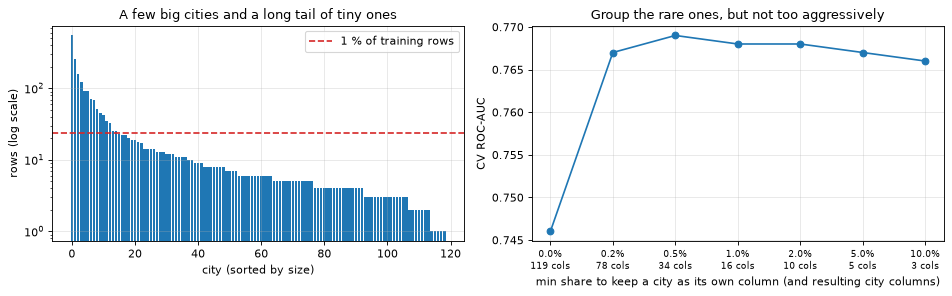

In [13]:
shares = [0.0, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]           # <- try other thresholds
rows = []
for share in shares:
    encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False,
                            min_frequency=share if share > 0 else None)
    n_columns = encoder.fit(train_fixed[["city"]]).transform(train_fixed[["city"]]).shape[1]
    auc = cv_auc(city_model(encoder), X_cat, y)
    rows.append({"min share": share, "city columns": n_columns, "CV ROC-AUC": round(auc, 3)})
sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))

grouper = OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False, min_frequency=0.01)
grouper.fit(train_fixed[["city"]])
new_city = pd.DataFrame({"city": ["city 999"]})
print("\na city never seen in training lands in:",
      [name for name, value in zip(grouper.get_feature_names_out(), grouper.transform(new_city)[0]) if value == 1])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(range(len(city_counts)), city_counts.to_numpy(), color="tab:blue")
axes[0].axhline(0.01 * len(train_fixed), color="tab:red", ls="--", label="1 % of training rows")
axes[0].set_yscale("log"); axes[0].set_xlabel("city (sorted by size)"); axes[0].set_ylabel("rows (log scale)")
axes[0].set_title("A few big cities and a long tail of tiny ones"); axes[0].legend()
axes[1].plot(range(len(sweep)), sweep["CV ROC-AUC"], marker="o")
axes[1].set_xticks(range(len(sweep)), [f"{share:.1%}\n{cols} cols" for share, cols in
                                       zip(sweep["min share"], sweep["city columns"])], fontsize=8)
axes[1].set_xlabel("min share to keep a city as its own column (and resulting city columns)")
axes[1].set_ylabel("CV ROC-AUC")
axes[1].set_title("Group the rare ones, but not too aggressively")
plt.tight_layout(); plt.show()

> **How to read this**
> * Left: 15 cities have at least 1 % of the training rows (24 or more); the long tail has a handful of rows each. A
>   one-hot column for a city with 3 rows is a column the model can only memorise.
> * Right / table: keeping every city gives **119 columns** and **0.746**. Grouping cities under 1 % into one
>   "infrequent" column leaves **16** columns (15 cities + "infrequent") and scores **0.768**; the best here is 0.5 %
>   (34 columns, **0.769**). Most of the gain comes from removing the tiniest cities.
> * **When it hurts:** at 10 % only the 2 biggest cities keep their own column (3 columns, **0.766**); every other
>   city, high-churn or low-churn, is lumped together. The loss is small here, but it is the direction to watch:
>   the curve is flat between 0.2 % and 5 % and drops at both ends.
> * A city never seen in training is mapped to the "infrequent" column instead of crashing the model — rare-category
>   grouping also prepares you for new categories in production.
> * **Leakage:** which categories count as rare is learned from data (counts only, no labels, so the risk is low).
>   Still, learn it on training rows only.

<a id="lab-12"></a>
## Lab 12 · Date / time features (including cyclical sin / cos)

**Goal:** a date is not a number a model can use, but several useful numbers hide inside it: how long ago it was,
and the month (which is *circular*: December is next to January).

churn share by sign-up month: {1: 0.61, 2: 0.58, 3: 0.56, 4: 0.51, 5: 0.41, 6: 0.33, 7: 0.34, 8: 0.4, 9: 0.45, 10: 0.59, 11: 0.64, 12: 0.61}

CV ROC-AUC (logistic regression):
  base columns (no dates)              0.745
  + tenure, days since last login      0.771
    + month as a number 1..12          0.771
    + month one-hot (12 columns)       0.797
    + month as sin, cos (2 columns)    0.803
    + sin, cos + weekday sin, cos      0.803


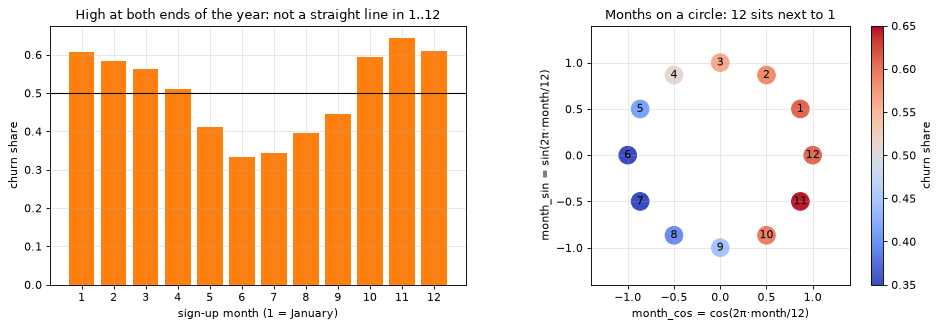

In [14]:
REFERENCE_DAY = pd.Timestamp("2025-01-01")                      # the day the table was exported
signup = train_fixed["signup_date"]
month = signup.dt.month
X_dates = X_base.assign(tenure_days=(REFERENCE_DAY - signup).dt.days,
                        days_since_login=(REFERENCE_DAY - train_fixed["last_login_date"]).dt.days)
churn_by_month = y.groupby(month).mean()
print("churn share by sign-up month:", churn_by_month.round(2).to_dict())

month_sin, month_cos = np.sin(2 * np.pi * month / 12), np.cos(2 * np.pi * month / 12)
variants = {
    "base columns (no dates)": X_base,
    "+ tenure, days since last login": X_dates,
    "  + month as a number 1..12": X_dates.assign(month=month),
    "  + month one-hot (12 columns)": X_dates.join(pd.get_dummies(month, prefix="m", dtype=int)),
    "  + month as sin, cos (2 columns)": X_dates.assign(month_sin=month_sin, month_cos=month_cos),
    "  + sin, cos + weekday sin, cos": X_dates.assign(
        month_sin=month_sin, month_cos=month_cos,
        weekday_sin=np.sin(2 * np.pi * signup.dt.day_of_week / 7), weekday_cos=np.cos(2 * np.pi * signup.dt.day_of_week / 7)),
}
print("\nCV ROC-AUC (logistic regression):")
for name, X in variants.items():
    print(f"  {name:36s} {cv_auc(linear_model(), X, y):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(churn_by_month.index, churn_by_month.to_numpy(), color="tab:orange")
axes[0].axhline(0.5, color="black", lw=1)
axes[0].set_xticks(range(1, 13)); axes[0].set_xlabel("sign-up month (1 = January)"); axes[0].set_ylabel("churn share")
axes[0].set_title("High at both ends of the year: not a straight line in 1..12")
points = axes[1].scatter(np.cos(2 * np.pi * churn_by_month.index / 12), np.sin(2 * np.pi * churn_by_month.index / 12),
                         c=churn_by_month.to_numpy(), cmap="coolwarm", s=250, vmin=0.35, vmax=0.65)
for m in churn_by_month.index:
    axes[1].annotate(str(m), (np.cos(2 * np.pi * m / 12), np.sin(2 * np.pi * m / 12)), ha="center", va="center")
axes[1].set_aspect("equal"); axes[1].set_xlim(-1.4, 1.4); axes[1].set_ylim(-1.4, 1.4)
axes[1].set_xlabel("month_cos = cos(2π·month/12)"); axes[1].set_ylabel("month_sin = sin(2π·month/12)")
axes[1].set_title("Months on a circle: 12 sits next to 1")
fig.colorbar(points, ax=axes[1], label="churn share")
plt.tight_layout(); plt.show()

> **How to read this**
> * Turning the two dates into **tenure** (days since sign-up) and **days since last login** is the biggest single
>   gain so far: **0.745** → **0.771**.
> * The churn share by month is high from October to January (**0.59–0.64**) and low in June–July (**0.33–0.34**).
>   As a number 1..12, December (12) and January (1) are as far apart as possible, so a linear model can't use it:
>   **0.771**, no gain at all. One-hot works (**0.797**) but spends 12 columns. **sin / cos** places the months on a
>   circle (right plot), puts 12 next to 1, and does better with only 2 columns: **0.803**.
> * **When it doesn't help:** the day of the week has no effect in this data; adding it as sin / cos leaves the score
>   at **0.803** and adds two useless columns.
> * **Which models care:** linear models and k-NN need the circle trick; trees can carve "month ≥ 11 or ≤ 2" out of the
>   plain number with two splits, so for them the number is usually fine.
> * **Leakage:** measure "days since" from a fixed reference day (the export date), never from `today()` (the
>   feature would drift every day). And only use dates known at prediction time.

---
<a id="part-d"></a>
# Part D — Creating features

<a id="lab-13"></a>
## Lab 13 · Domain features: ratios, differences, aggregates, keyword flags

**Goal:** build features from what you know about the business, and check each one. The starting point is the
best table so far (call it `X_time`): base columns + the income "was missing" flag (Lab 6) + tenure, days since last
login and month as sin / cos (Lab 12).

churn share by decile of charges_to_income (1 = cheapest relative to income):
{1: 0.34, 2: 0.32, 3: 0.34, 4: 0.31, 5: 0.4, 6: 0.4, 7: 0.47, 8: 0.52, 9: 0.58, 10: 0.74}

churn share when the support note mentions the word: {'billing': 0.65, 'slow': 0.58, 'crash': 0.66, 'thanks': 0.29, 'love': 0.31}

CV ROC-AUC              logistic   trees


  X_time                                0.822   0.837


  + charges_to_income (ratio)           0.827   0.839


  + keyword flags (5 columns)           0.842   0.852


  + income vs city median (aggregate)   0.823   0.840


  + active days (difference)            0.822   0.836


  + 56 unthinking ratios                0.850   0.837


  + the 42 of them without age          0.829   0.841


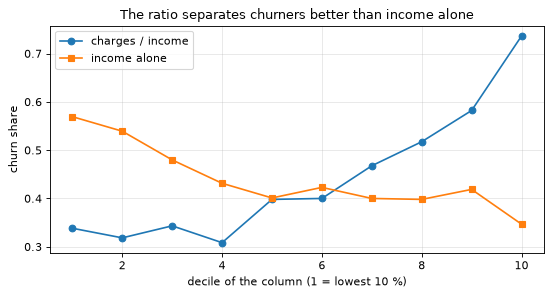

In [15]:
X_time = X_dates.assign(income_was_missing=train_fixed["monthly_income"].isna().astype(int),
                        month_sin=month_sin, month_cos=month_cos)
ratio = (train_fixed["monthly_charges"] / train_fixed["monthly_income"]).rename("charges_to_income")
print("churn share by decile of charges_to_income (1 = cheapest relative to income):")
print(y.groupby(pd.qcut(ratio, 10, labels=range(1, 11))).mean().round(2).to_dict())

notes = train_fixed["support_note"].fillna("")
WORDS = ["billing", "slow", "crash", "thanks", "love"]                  # <- try other words
keyword_flags = pd.DataFrame({f"note_{w}": notes.str.contains(w).astype(int) for w in WORDS})
print("\nchurn share when the support note mentions the word:",
      {w: round(float(y[keyword_flags[f"note_{w}"] == 1].mean()), 2) for w in WORDS})

city_median_income = train_fixed.groupby("city")["monthly_income"].transform("median")
income_vs_city = (train_fixed["monthly_income"] / city_median_income).rename("income_vs_city")
active_days = (X_time["tenure_days"] - X_time["days_since_login"]).rename("active_days")

# "Feature soup": every pairwise ratio of 8 numeric columns, without thinking
soup_columns = ["age", "monthly_income", "monthly_charges", "total_spend", "num_support_calls", "weekly_logins",
                "avg_session_minutes", "tenure_days"]
soup = pd.DataFrame({f"{a}/{b}": X_time[a] / X_time[b].replace(0, np.nan)
                     for a in soup_columns for b in soup_columns if a != b})

variants = {
    "X_time": X_time,
    "+ charges_to_income (ratio)": X_time.join(ratio),
    "+ keyword flags (5 columns)": X_time.join(keyword_flags),
    "+ income vs city median (aggregate)": X_time.join(income_vs_city),
    "+ active days (difference)": X_time.join(active_days),
    "+ 56 unthinking ratios": X_time.join(soup),
    "+ the 42 of them without age": X_time.join(soup[[c for c in soup.columns if "age" not in c]]),
}
print("\nCV ROC-AUC              logistic   trees")
for name, X in variants.items():
    print(f"  {name:37s} {cv_auc(linear_model(), X, y):.3f}   {cv_auc(tree_model(), X, y):.3f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
deciles = pd.qcut(ratio, 10, labels=range(1, 11))
ax.plot(range(1, 11), y.groupby(deciles).mean().to_numpy(), marker="o", label="charges / income")
ax.plot(range(1, 11), y.groupby(pd.qcut(train_fixed["monthly_income"], 10, labels=range(1, 11))).mean().to_numpy(),
        marker="s", label="income alone")
ax.set_xlabel("decile of the column (1 = lowest 10 %)"); ax.set_ylabel("churn share")
ax.set_title("The ratio separates churners better than income alone"); ax.legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * Churn climbs with the price-to-income ratio: about **0.31–0.34** in the four cheapest deciles, **0.74** in the
>   most expensive one. Income alone tells a weaker, noisier story (plot): the ratio is the quantity customers feel.
> * Yet adding the ratio lifts the linear model only from **0.822** to **0.827** (trees 0.837 → 0.839). The table
>   already holds both ingredients, income and charges, and the model can partly combine them itself. A domain
>   feature adds most when the model can't build it on its own.
> * The **keyword flags** are the big win here: **0.842** (trees **0.852**). Notes mentioning billing, slowness or
>   crashes belong to churners (0.58–0.66), notes with "thanks" or "love" to customers who stay (0.29–0.31). Five
>   0/1 columns pulled out of free text.
> * **When it doesn't help:** income relative to the city median (an *aggregate*, **0.823**) and active days (a
>   *difference*, **0.822**) carry no real effect in this data, so they add nothing. Sensible-sounding features still
>   have to earn their place.
> * **The "feature soup" trap:** all 56 pairwise ratios of 8 columns, made without thinking, score **0.850** — better
>   than any single idea! But without the 14 ratios involving age they score **0.829**. The soup works because
>   ratios like `tenure_days / age` *bend* the age effect, accidentally approximating the real U shape in age that
>   Lab 14 finds. Lab 14 shows that once the real shape is added, the soup stops helping. A pile of features that
>   "works" without you knowing why is a pile you can't trust.
> * **Leakage:** group statistics (here the city median income) are learned from data: compute them on training rows
>   only. A group statistic of the **target** (a city's churn rate) is target encoding (Lab 10) and needs cross-fitting.

<a id="lab-14"></a>
## Lab 14 · Interactions and polynomials

**Goal:** give a linear model the two shapes it cannot draw by itself — a U (age) and an "it depends" effect
(support calls hurt premium customers more) — and see what happens when you add *all* products blindly.

CV ROC-AUC                         logistic   trees


  X_dom (+ plan rank)              0.845   0.854


  + age squared                    0.872   0.852


  + premium x log(calls)           0.854   0.855


  + both                           0.879   0.855


  + both + the 56 ratios of Lab 13 0.874   0.856

all products and squares of 28 columns (435 columns): CV ROC-AUC 0.830


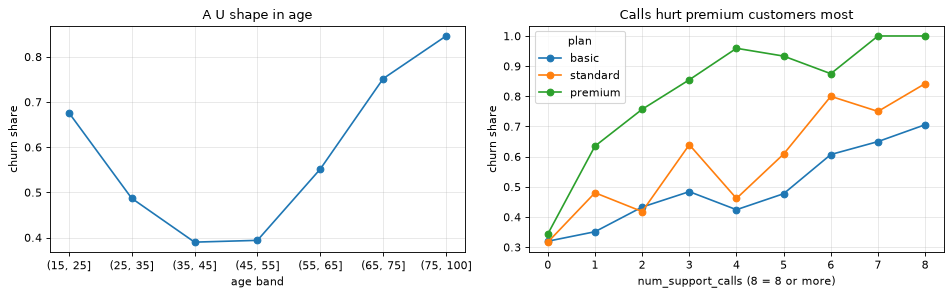

In [16]:
X_dom = X_time.join(ratio).join(keyword_flags)                  # everything that helped so far
plan_rank = train_fixed["plan"].map(PLAN_ORDER)
premium = (plan_rank == 2).astype(int)
age_centred = X_dom["age"] - X_dom["age"].mean()                 # centre first, so age² is not a copy of age
calls_log = np.log1p(X_dom["num_support_calls"])

variants = {
    "X_dom (+ plan rank)": X_dom.assign(plan_rank=plan_rank),
    "+ age squared": X_dom.assign(plan_rank=plan_rank, age_squared=age_centred ** 2),
    "+ premium x log(calls)": X_dom.assign(plan_rank=plan_rank, premium_x_calls=premium * calls_log),
    "+ both": X_dom.assign(plan_rank=plan_rank, age_squared=age_centred ** 2, premium_x_calls=premium * calls_log),
    "+ both + the 56 ratios of Lab 13": X_dom.assign(plan_rank=plan_rank, age_squared=age_centred ** 2,
                                                   premium_x_calls=premium * calls_log).join(soup),
}
print("CV ROC-AUC                         logistic   trees")
for name, X in variants.items():
    print(f"  {name:32s} {cv_auc(linear_model(), X, y):.3f}   {cv_auc(tree_model(), X, y):.3f}")

blind = X_dom.assign(plan_rank=plan_rank)
poly = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PolynomialFeatures(degree=2),
                     StandardScaler(), LogisticRegression(max_iter=5000))
n_poly = PolynomialFeatures(degree=2).fit(blind.fillna(0)).n_output_features_
print(f"\nall products and squares of {blind.shape[1]} columns ({n_poly} columns): CV ROC-AUC {cv_auc(poly, blind, y):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
age_band = pd.cut(X_dom["age"], [15, 25, 35, 45, 55, 65, 75, 100])
axes[0].plot([str(b) for b in age_band.cat.categories], y.groupby(age_band, observed=False).mean().to_numpy(), marker="o")
axes[0].set_xlabel("age band"); axes[0].set_ylabel("churn share"); axes[0].set_title("A U shape in age")
calls_band = X_dom["num_support_calls"].clip(upper=8)
for plan, rank in PLAN_ORDER.items():
    rows = plan_rank == rank
    axes[1].plot(y[rows].groupby(calls_band[rows]).mean(), marker="o", label=plan)
axes[1].set_xlabel("num_support_calls (8 = 8 or more)"); axes[1].set_ylabel("churn share")
axes[1].set_title("Calls hurt premium customers most"); axes[1].legend(title="plan")
plt.tight_layout(); plt.show()

> **How to read this**
> * Left plot: churn is high for the youngest and oldest customers and lowest between 35 and 55 — a U. A linear
>   model with plain `age` can only draw a straight line. Adding the centred square lifts it from **0.845** to **0.872**.
> * Right plot: the line for premium customers climbs much faster with support calls than the other two. That is
>   an **interaction**: the effect of calls depends on the plan. The product column gives **0.854**; both: **0.879**.
> * Now the Lab 13 soup: on top of both real features, the 56 ratios *lower* the score (**0.879 → 0.874**). Once the
>   true shape is there, they are just noise.
> * Trees barely move (**0.854 → 0.855**): a tree builds interactions by itself (split on plan, then on calls) and
>   U shapes too (split age twice). Engineered interactions mostly help linear models.
> * **When it hurts:** all products and squares of the 28 columns give **435** columns and **0.830** — far below the
>   two hand-picked terms. With 2,400 rows, hundreds of columns let the model fit noise. Add the interactions you
>   have a reason for, then check them.

<a id="lab-15"></a>
## Lab 15 · Binning

**Goal:** cut a numeric column into ranges and give each range its own weight. Compare with the square from Lab 14,
and see when binning throws information away.

CV ROC-AUC, logistic regression:


  age as a straight line             0.854
  age + age squared                  0.879
  age in  3 bins                     0.858
  age in  5 bins                     0.871


  age in 10 bins                     0.874

toy with a smooth straight-line effect of x:


  x as a number                      0.871
  x in  3 bins                       0.856
  x in 10 bins                       0.868



trees: age as a number 0.855, age in 5 bins 0.844


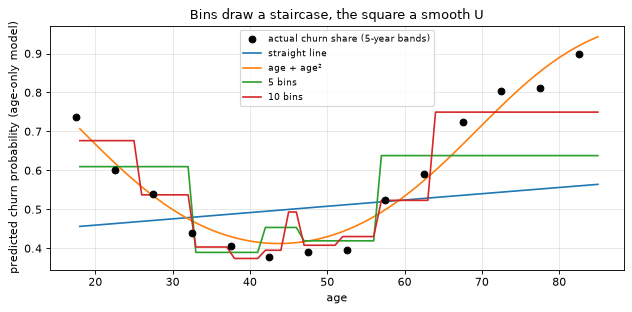

In [17]:
from sklearn.preprocessing import KBinsDiscretizer


def binned(columns, n_bins):
    """Column step: fill gaps, then one-hot quantile bins for `columns`; other columns pass through."""
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"),
                       KBinsDiscretizer(n_bins=n_bins, encode="onehot-dense", strategy="quantile",
                                        quantile_method="averaged_inverted_cdf")), columns),
        remainder="passthrough")


X_bin = X_dom.assign(plan_rank=plan_rank, premium_x_calls=premium * calls_log)
print("CV ROC-AUC, logistic regression:")
print(f"  age as a straight line             {cv_auc(linear_model(), X_bin, y):.3f}")
print(f"  age + age squared                  {cv_auc(linear_model(), X_bin.assign(age_squared=age_centred ** 2), y):.3f}")
for n_bins in [3, 5, 10]:                                        # <- try other numbers of bins
    print(f"  age in {n_bins:2d} bins                     {cv_auc(linear_model(binned(['age'], n_bins)), X_bin, y):.3f}")

# When binning HURTS: a column whose effect is a smooth straight line.
rng = np.random.default_rng(SEED)
toy = pd.DataFrame({"x": rng.uniform(-1, 1, 3000), "other": rng.normal(0, 1, 3000)})
smooth = (rng.random(3000) < 1 / (1 + np.exp(-(3 * toy["x"] + toy["other"])))).astype(int)
print("\ntoy with a smooth straight-line effect of x:")
print(f"  x as a number                      {cv_auc(linear_model(), toy, smooth):.3f}")
for n_bins in [3, 10]:
    print(f"  x in {n_bins:2d} bins                       {cv_auc(linear_model(binned(['x'], n_bins)), toy, smooth):.3f}")
print(f"\ntrees: age as a number {cv_auc(tree_model(), X_bin, y):.3f}, "
      f"age in 5 bins {cv_auc(make_pipeline(binned(['age'], 5), tree_model()), X_bin, y):.3f}")

ages = pd.DataFrame({"age": np.arange(18, 86)})
only_age = X_bin[["age"]]
fig, ax = plt.subplots(figsize=(8, 4))
band = pd.cut(only_age["age"], np.arange(15, 90, 5))
actual = y.groupby(band, observed=True).mean()
ax.scatter([b.mid for b in actual.index], actual.to_numpy(), color="black", zorder=3, label="actual churn share (5-year bands)")
for label, model in [("straight line", linear_model()), ("age + age²", linear_model(SimpleImputer(strategy="median"), PolynomialFeatures(2))),
                     ("5 bins", linear_model(binned(["age"], 5))), ("10 bins", linear_model(binned(["age"], 10)))]:
    ax.plot(ages["age"], model.fit(only_age, y).predict_proba(ages)[:, 1], label=label)
ax.set_xlabel("age"); ax.set_ylabel("predicted churn probability (age-only model)")
ax.set_title("Bins draw a staircase, the square a smooth U"); ax.legend(fontsize=8, loc="upper center")
plt.tight_layout(); plt.show()

> **How to read this**
> * Age as a straight line: **0.854**. Bins let each age range have its own effect: 3 bins **0.858**, 5 bins
>   **0.871**, 10 bins **0.874**. The square from Lab 14 still wins (**0.879**): when you know the shape, a formula
>   uses the data more efficiently than bins.
> * The plot shows the shapes each version can draw from age alone: a straight line (misses the U), a smooth U
>   (age²) and staircases (bins). More bins follow the data more closely but each step is estimated from fewer rows.
> * **When it hurts:** if the effect is a smooth straight line, bins only throw away detail: in the toy, x as a number
>   scores **0.871**, 3 bins **0.856**, 10 bins **0.868**. Every customer inside a bin is treated the same.
> * Trees don't need binning, and fixed bins even hurt them (**0.855** vs **0.844**): a tree *is* a set of learned
>   bins, and choosing the edges for it removes its freedom to put them in the right places.
> * **Leakage:** quantile bin edges are learned from data; `KBinsDiscretizer` inside the pipeline learns them on the
>   training folds only.

---
<a id="part-e"></a>
# Part E — Fewer, better features

<a id="lab-16"></a>
## Lab 16 · Correlated and redundant features: correlation, VIF

**Goal:** find columns that repeat each other, measure how much (correlation, VIF), and see what redundancy does to
a linear model's weights — and to its score. The table is everything that helped so far (`X_eng`).

<details>
<summary><b>What VIF measures (click to expand)</b></summary>

The **variance inflation factor** of a column asks: *how well can the other columns predict this one?*
Fit a linear regression of column $j$ on all the other columns and take its $R^2$ (the share of column $j$'s
variance it explains, between 0 and 1). Then

$$\text{VIF}_j = \frac{1}{1 - R^2_j}$$

* $R^2_j = 0$ (nothing predicts it) → VIF = 1: no redundancy.
* $R^2_j = 0.9$ → VIF = 10: a common "worry" threshold.
* $R^2_j = 0.99$ → VIF = 100: the column is almost a copy of a mix of the others.

The name comes from linear regression: the uncertainty (variance) of column $j$'s weight is multiplied by exactly
this factor compared with a column that is unrelated to the others. Correlation only looks at **pairs**; VIF also
catches a column that is a mix of *several* others (e.g. `total_spend` ≈ price × tenure).
</details>

pairs with |correlation| > 0.7:
  weekly_logins          monthly_logins         +1.00
  monthly_charges        plan_rank              +0.97

highest VIFs:
monthly_logins     139.1
weekly_logins      139.0
monthly_charges     23.1
plan_rank           18.3
total_spend          7.9
tenure_days          4.9



weight of weekly_logins, with monthly_logins   : mean +0.206, spread (std) 0.345

weight of weekly_logins, monthly_logins dropped: mean -0.147, spread (std) 0.069

CV ROC-AUC with monthly_logins 0.879, without 0.879


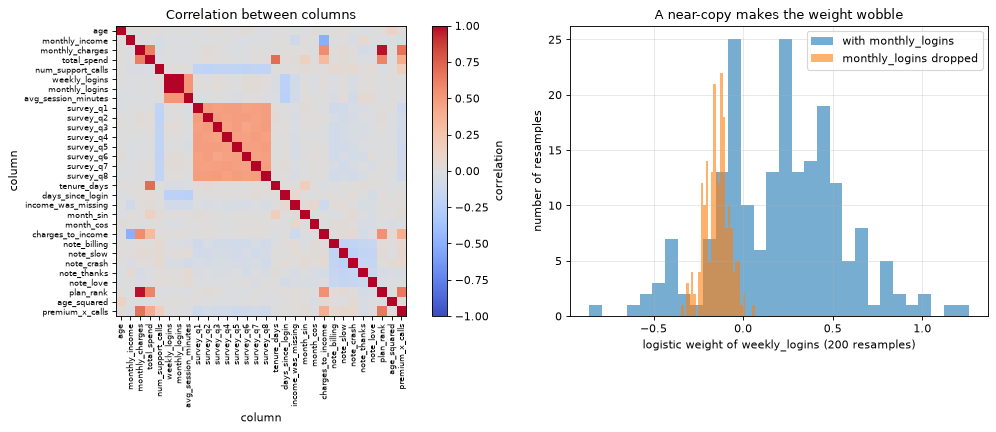

In [18]:
X_eng = X_dom.assign(plan_rank=plan_rank, age_squared=age_centred ** 2, premium_x_calls=premium * calls_log)
filled = X_eng.fillna(X_eng.median())

corr = filled.corr()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
         if abs(corr.loc[a, b]) > 0.7]
print("pairs with |correlation| > 0.7:")
for a, b, r in sorted(pairs, key=lambda p: -abs(p[2])):
    print(f"  {a:22s} {b:22s} {r:+.2f}")


def vif(frame):
    """VIF of every column: 1 / (1 - R²) of a linear regression on all the other columns."""
    values = {}
    for column in frame.columns:
        others = frame.drop(columns=column)
        r2 = LinearRegression().fit(others, frame[column]).score(others, frame[column])
        values[column] = 1 / (1 - r2)
    return pd.Series(values).sort_values(ascending=False)


print("\nhighest VIFs:")
print(vif(filled).head(6).round(1).to_string())

# Instability: refit on 200 bootstrap resamples, watch the weight of weekly_logins
rng = np.random.default_rng(SEED)
weights = {"with monthly_logins": [], "monthly_logins dropped": []}
for _ in range(200):
    rows = rng.integers(0, len(filled), len(filled))
    for label, X in [("with monthly_logins", filled), ("monthly_logins dropped", filled.drop(columns="monthly_logins"))]:
        model = linear_model().fit(X.iloc[rows], y.iloc[rows])
        weights[label].append(model[-1].coef_[0][list(X.columns).index("weekly_logins")])
for label, w in weights.items():
    print(f"\nweight of weekly_logins, {label:22s}: mean {np.mean(w):+.3f}, spread (std) {np.std(w):.3f}")
print(f"\nCV ROC-AUC with monthly_logins {cv_auc(linear_model(), X_eng, y):.3f}, "
      f"without {cv_auc(linear_model(), X_eng.drop(columns='monthly_logins'), y):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.25, 1]})
image = axes[0].imshow(corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
axes[0].set_yticks(range(len(corr)), corr.columns, fontsize=7)
axes[0].set_xlabel("column"); axes[0].set_ylabel("column"); axes[0].set_title("Correlation between columns")
axes[0].grid(False)
fig.colorbar(image, ax=axes[0], label="correlation")
for label, w in weights.items():
    axes[1].hist(w, bins=30, alpha=0.6, label=label)
axes[1].set_xlabel("logistic weight of weekly_logins (200 resamples)"); axes[1].set_ylabel("number of resamples")
axes[1].set_title("A near-copy makes the weight wobble"); axes[1].legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * Only two pairs are strongly correlated: `weekly_logins` / `monthly_logins` (**+1.00** after rounding: one is ~4.3×
>   the other) and `monthly_charges` / `plan_rank` (**+0.97**: the price is set by the plan). The heatmap's other
>   bright block is the 8 survey questions (moderately correlated with each other, because they all measure
>   satisfaction).
> * VIF agrees and adds one: the logins pair has VIF **139**, charges **23.1**, plan rank **18.3**, and `total_spend`
>   **7.9** — not a copy of any single column, but largely a mix of price and tenure.
> * The weight wobble: with both logins columns, the weight of `weekly_logins` over 200 resamples has mean **+0.206**
>   and spread **0.345** — it even changes sign between resamples, because the model can shift credit freely between
>   the two copies. With the copy dropped: mean **−0.147**, spread **0.069**, five times steadier (right plot).
> * But the **score** doesn't change (**0.879** vs **0.879**): the two columns together carry the same
>   information as one. Redundancy hurts **interpretation** and **stability**, not usually prediction.
> * **Which models care:** linear models (unstable weights, misleading "importance"); trees split the importance
>   between the copies, so a feature-importance chart can make both look half as important as they are.
> * **When not to drop:** two correlated columns can still each carry their own information (the survey questions
>   correlate at about 0.4–0.5 but each adds a little). Drop near-copies; compress groups (Lab 18).

<a id="lab-17"></a>
## Lab 17 · Feature selection: filter, wrapper, embedded (and the classic leak)

**Goal:** keep only the columns that help, with the three families of methods, and catch the most common
mistake in all of machine learning: **choosing the columns before splitting**. Five pure-noise "vendor score"
columns are added so there is something worth removing.

In [19]:
X_sel = X_eng.join(train_fixed[[f"ext_score_{i}" for i in range(1, 6)]])


def mutual_info(X, y):
    """Mutual information of each column with the target (fixed seed, so results repeat)."""
    return mutual_info_classif(X, y, random_state=SEED)


def selected_model(selector):
    """Fill gaps, standardise, select columns with `selector`, logistic regression - all inside the pipeline."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), selector, LogisticRegression(max_iter=5000))


prepared = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X_sel))
scores = pd.Series(mutual_info(prepared, y), index=X_sel.columns).sort_values(ascending=False)
print("filter - mutual information with the target (top 6, bottom 6):")
print(pd.concat([scores.head(6), scores.tail(6)]).round(4).to_string())

print(f"\nall {X_sel.shape[1]} columns                         : CV ROC-AUC {cv_auc(linear_model(), X_sel, y):.3f}")
for k in [5, 10, 20]:                                             # <- try other k
    print(f"filter   (best {k:2d} by mutual information)  : CV ROC-AUC "
          f"{cv_auc(selected_model(SelectKBest(mutual_info, k=k)), X_sel, y):.3f}")
print(f"wrapper  (RFE down to 20 columns)          : CV ROC-AUC "
      f"{cv_auc(selected_model(RFE(LogisticRegression(max_iter=5000), n_features_to_select=20)), X_sel, y):.3f}")
lasso = LogisticRegression(l1_ratio=1.0, C=0.05, solver="liblinear")          # <- try C (smaller = fewer columns)
print(f"embedded (L1 / lasso, C = 0.05)            : CV ROC-AUC {cv_auc(selected_model(SelectFromModel(lasso)), X_sel, y):.3f}")
kept = SelectFromModel(lasso).fit(prepared, y).get_support()
print(f"  lasso on all training rows keeps {kept.sum()} of {len(kept)}; dropped: {list(X_sel.columns[~kept])}")

# THE CLASSIC LEAK: pure noise, 2,000 random columns, random labels. There is NOTHING to find.
rng = np.random.default_rng(SEED)
noise_X, noise_y = rng.normal(size=(500, 2000)), rng.integers(0, 2, 500)
chosen = SelectKBest(k=20).fit(noise_X, noise_y).get_support()          # chosen using ALL 500 rows
print(f"\nnoise: select 20 columns on ALL rows, then CV : ROC-AUC "
      f"{cv_auc(LogisticRegression(max_iter=5000), noise_X[:, chosen], noise_y):.3f}")
print(f"noise: select 20 columns INSIDE each fold     : ROC-AUC "
      f"{cv_auc(make_pipeline(SelectKBest(k=20), LogisticRegression(max_iter=5000)), noise_X, noise_y):.3f}")

filter - mutual information with the target (top 6, bottom 6):
charges_to_income    0.0507
monthly_income       0.0500
num_support_calls    0.0461
premium_x_calls      0.0448
age                  0.0418
survey_q8            0.0411
month_sin            0.0043
note_slow            0.0041
note_love            0.0007
ext_score_2          0.0000
ext_score_4          0.0000
ext_score_5          0.0000

all 35 columns                         : CV ROC-AUC 0.878


filter   (best  5 by mutual information)  : CV ROC-AUC 0.732


filter   (best 10 by mutual information)  : CV ROC-AUC 0.794


filter   (best 20 by mutual information)  : CV ROC-AUC 0.859
wrapper  (RFE down to 20 columns)          : CV ROC-AUC 0.876


embedded (L1 / lasso, C = 0.05)            : CV ROC-AUC 0.879
  lasso on all training rows keeps 24 of 35; dropped: ['monthly_income', 'monthly_charges', 'total_spend', 'num_support_calls', 'weekly_logins', 'survey_q3', 'plan_rank', 'ext_score_2', 'ext_score_3', 'ext_score_4', 'ext_score_5']

noise: select 20 columns on ALL rows, then CV : ROC-AUC 0.760
noise: select 20 columns INSIDE each fold     : ROC-AUC 0.450


> **How to read this**
> * **Filter:** mutual information (how much knowing a column reduces uncertainty about the target) ranks the ratio,
>   income, calls and the interaction at the top, and gives the noise columns `ext_score_2/4/5` exactly **0**.
>   But scoring one column at a time misses teamwork: keeping only the best 5 drops to **0.732**, best 10 **0.794**,
>   best 20 **0.859**, against **0.878** with all 35. Columns that look weak alone (month sin / cos) matter in
>   combination.
> * **Wrapper:** RFE refits the model, drops the weakest column and repeats until 20 remain: **0.876**, almost no
>   loss with 15 fewer columns. Slow, because it trains the model many times.
> * **Embedded:** the lasso keeps **24 of 35** columns and scores **0.879**, equal to using everything. It drops four
>   of the five noise columns, and also raw columns whose information is already inside engineered ones (income and
>   charges live on in `charges_to_income`, calls in `premium_x_calls`). Fewer columns, same score: simpler to
>   explain and cheaper to run.
> * **The classic leak:** 2,000 columns of pure noise and random labels — there is nothing to learn. Choosing the 20
>   "best" columns using all 500 rows, *then* cross-validating, gives ROC-AUC **0.760**: the selection already
>   looked at the validation rows' labels and kept the columns that happen to match them. Doing the selection inside
>   each fold gives **0.450**: a coin flip, give or take chance (on pure noise a score below 0.5 is as likely as
>   one above). That is the truth. This mistake has appeared in published research; the fix is simply to
>   put selection inside the pipeline.
> * **Which models care:** k-NN and linear models without regularisation suffer most from useless columns; L1/L2
>   regularisation and trees cope better on their own, so selection matters less for them.

<a id="lab-18"></a>
## Lab 18 · Dimensionality reduction: PCA, and LDA when labels exist

**Goal:** compress a *group* of related columns. The 8 survey questions all measure one hidden thing
(satisfaction), each with noise. Can one column replace eight? Then compare PCA (ignores the label) with LDA
(uses it) on a scikit-learn toy dataset. The PCA notes are in [`../../PCA/README.md`](../../PCA/README.md).

survey block - share of variance per principal component: [0.53 0.07 0.07 0.07 0.07 0.06 0.06 0.06]
PC1 weights (loadings): [0.36 0.36 0.35 0.35 0.36 0.35 0.35 0.36]

CV ROC-AUC, logistic regression:
  no survey columns            0.854
  all 8 survey columns         0.879
  survey -> PCA, 1 column      0.879


  survey -> LDA, 1 column      0.879
  survey -> plain average      0.879



breast cancer, 30 columns -> PCA 1 column: CV ROC-AUC 0.971

breast cancer, 30 columns -> LDA 1 column: CV ROC-AUC 0.993
breast cancer, all 30 columns           : CV ROC-AUC 0.995



trees on X_eng                     : CV ROC-AUC 0.855


trees on PCA (95 % variance) of it : CV ROC-AUC 0.849


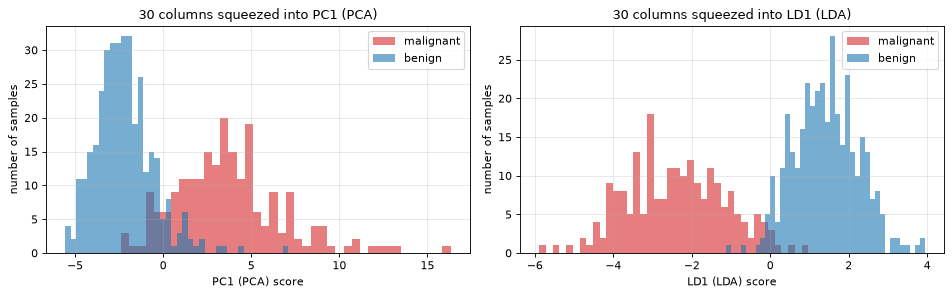

In [20]:
SURVEY = [f"survey_q{i}" for i in range(1, 9)]
pca = PCA().fit(StandardScaler().fit_transform(X_eng[SURVEY]))
print("survey block - share of variance per principal component:", pca.explained_variance_ratio_.round(2))
print("PC1 weights (loadings):", pca.components_[0].round(2))

without_survey = X_eng.drop(columns=SURVEY)


def block_model(block_step):
    """Linear model where the survey block is replaced by `block_step` (fitted inside the pipeline)."""
    return linear_model(make_column_transformer((make_pipeline(StandardScaler(), block_step), SURVEY),
                                                remainder="passthrough"))


print("\nCV ROC-AUC, logistic regression:")
print(f"  no survey columns            {cv_auc(linear_model(), without_survey, y):.3f}")
print(f"  all 8 survey columns         {cv_auc(linear_model(), X_eng, y):.3f}")
print(f"  survey -> PCA, 1 column      {cv_auc(block_model(PCA(n_components=1)), X_eng, y):.3f}")
print(f"  survey -> LDA, 1 column      {cv_auc(block_model(LinearDiscriminantAnalysis(n_components=1)), X_eng, y):.3f}")
print(f"  survey -> plain average      {cv_auc(linear_model(), without_survey.assign(survey_mean=X_eng[SURVEY].mean(axis=1)), y):.3f}")

# Toy dataset: 30 measurements of breast-tissue cells, benign vs malignant
cancer_X, cancer_y = load_breast_cancer(return_X_y=True)
for name, reducer in [("PCA", PCA(n_components=1)), ("LDA", LinearDiscriminantAnalysis(n_components=1))]:
    model = make_pipeline(StandardScaler(), reducer, LogisticRegression())
    print(f"\nbreast cancer, 30 columns -> {name} 1 column: CV ROC-AUC {cv_auc(model, cancer_X, cancer_y):.3f}")
print(f"breast cancer, all 30 columns           : CV ROC-AUC "
      f"{cv_auc(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), cancer_X, cancer_y):.3f}")

# When it HURTS: PCA on the whole table, then trees
print(f"\ntrees on X_eng                     : CV ROC-AUC {cv_auc(tree_model(), X_eng, y):.3f}")
print(f"trees on PCA (95 % variance) of it : CV ROC-AUC "
      f"{cv_auc(make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), PCA(0.95, random_state=SEED), tree_model()), X_eng, y):.3f}")

scaled_cancer = StandardScaler().fit_transform(cancer_X)                 # all rows: for the picture only
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, reducer) in zip(axes, [("PC1 (PCA)", PCA(n_components=1)), ("LD1 (LDA)", LinearDiscriminantAnalysis(n_components=1))]):
    scores_1d = reducer.fit_transform(scaled_cancer, cancer_y).ravel()
    for label, color, title in [(0, "tab:red", "malignant"), (1, "tab:blue", "benign")]:
        ax.hist(scores_1d[cancer_y == label], bins=40, alpha=0.6, color=color, label=title)
    ax.set_xlabel(f"{name} score"); ax.set_ylabel("number of samples"); ax.legend()
    ax.set_title(f"30 columns squeezed into {name}")
plt.tight_layout(); plt.show()

> **How to read this**
> * PC1 of the survey block holds **53 %** of its variance; every other component about 6–7 %. All 8 loadings are
>   equal (**0.35–0.36**): PC1 is essentially the average answer, i.e. the hidden satisfaction score.
> * Survey columns are worth something (**0.854** without them, **0.879** with all 8). Replacing all 8 by one PCA
>   column keeps **0.879**; so do one LDA column and the plain average. Eight columns → one, no loss.
> * Breast-cancer toy (30 columns → 1): PCA keeps the direction of largest spread (**0.971**), LDA the direction that
>   best separates the classes (**0.993**, close to all 30 columns' **0.995**). The histograms show it: the LD1
>   classes overlap less than the PC1 classes. With labels available, LDA is the better 1-D summary for
>   classification; for two classes it can give only **one** component.
> * **When it hurts:** PCA on the whole table before a tree model costs **0.855 → 0.849**: every PCA column mixes all
>   the original ones, and trees split best on the original, meaningful columns.
> * **Leakage:** PCA learns directions from the data and LDA also uses the labels, so both must be fitted on
>   training rows only — here they sit inside the pipeline. LDA has the same danger as Lab 17's selection: fitted on
>   all rows, it would look better than it is.

<a id="lab-19"></a>
## Lab 19 · Did my features help? Permutation importance and SHAP

**Goal:** after building and selecting features, check which ones the model actually relies on, with two tools:
**permutation importance** (shuffle one column on rows the model never saw: how much worse does it predict?) and
**SHAP values** (split each prediction into one contribution per column). Then three traps where importance charts
mislead: a leak, a near-copy, and the "impurity" importance that tree libraries report by default. The table is
Lab 17's `X_sel` (everything engineered so far plus the five pure-noise vendor scores); the model is the
gradient-boosted trees used throughout.

<details>
<summary><b>What permutation importance and SHAP compute (click to expand)</b></summary>

**Permutation importance.** Fit the model and score it on validation rows (here ROC-AUC). Then shuffle one column's
values across those rows, which breaks its link with the target but keeps its distribution, and score again. The
drop is that column's importance; the shuffle is repeated a few times and averaged. Here it is done on each CV fold's
validation rows and averaged over the 5 folds.

* It answers **"how much does the score depend on this column?"**, in the score's own units (AUC points).
* About 0 means the model predicts just as well without the column's information. It can come out slightly negative:
  by chance, shuffling a noise column can score a hair better.
* It must be measured on rows the model did not train on. On its own training rows, a model that memorised a noise
  column loses score when that column is shuffled, so the noise would look useful.
* Weakness: if another column carries the same information, shuffling one barely hurts, because the model still has
  the other (trap 2 below).

**SHAP values** (SHapley Additive exPlanations). For one row, the model's output (for these trees: the log-odds of
churn) is split into a **base value** (the average output) plus **one contribution per column**:

$$\text{model output}(x) = \text{base value} + \phi_1(x) + \phi_2(x) + \dots + \phi_p(x)$$

$\phi_j(x)$ is column $j$'s **Shapley value**, a fair-sharing rule from game theory: the average change in the output
when column $j$'s real value is revealed, averaged over every order in which the columns could be revealed one by one.
It is the only rule with a handful of fairness properties, among them: the parts always add up exactly to the output,
columns that play identical roles get equal credit, and a column that never changes the output gets 0. Computed
naively it needs every subset of columns ($2^p$ of them); for tree models **TreeSHAP** gets it fast by walking the
trees.

* $\phi > 0$ pushes this row towards churn, $\phi < 0$ away from it. **Mean |SHAP|** over many rows gives one
  importance number per column; plotting $\phi_j$ against column $j$'s value (a **dependence plot**) shows the shape of
  its effect.
* It answers **"how much does the model's output move with this column?"**: what the model **uses**, not whether that
  use helps on new rows. A column the model splits on, even pure noise, gets credit.
* Units here are log-odds: +0.69 doubles the odds of churn.

**In one line:** permutation importance measures **usefulness** for the score; SHAP measures **use** by the model,
row by row.

</details>

trees on X_sel (35 columns): CV ROC-AUC 0.856

column                  permutation: AUC drop   mean |SHAP| (log-odds)
charges_to_income             +0.0475 (# 1)            0.779 (# 1)
age_squared                   +0.0339 (# 2)            0.644 (# 2)
days_since_login              +0.0272 (# 3)            0.603 (# 3)
month_cos                     +0.0246 (# 4)            0.602 (# 4)
premium_x_calls               +0.0177 (# 5)            0.334 (# 6)
tenure_days                   +0.0124 (# 6)            0.410 (# 5)
note_thanks                   +0.0099 (# 7)            0.235 (# 9)
note_love                     +0.0074 (# 8)            0.193 (#13)
ext_score_1                   +0.0017 (#19)            0.131 (#16)
ext_score_2                   +0.0002 (#28)            0.074 (#28)
ext_score_3                   +0.0002 (#27)            0.099 (#24)
ext_score_4                   -0.0003 (#34)            0.108 (#22)
ext_score_5                   +0.0021 (#15)            0.105 (#23)



customer row 871: base +0.058 + SHAP sum +5.220 = +5.278 log-odds; model says +5.278 (churn probability 0.99, actually churned: 1)
biggest contributions: {'tenure_days': 1.7, 'charges_to_income': 1.3, 'month_cos': 0.77, 'total_spend': 0.67, 'days_since_login': 0.6, 'ext_score_2': -0.33}


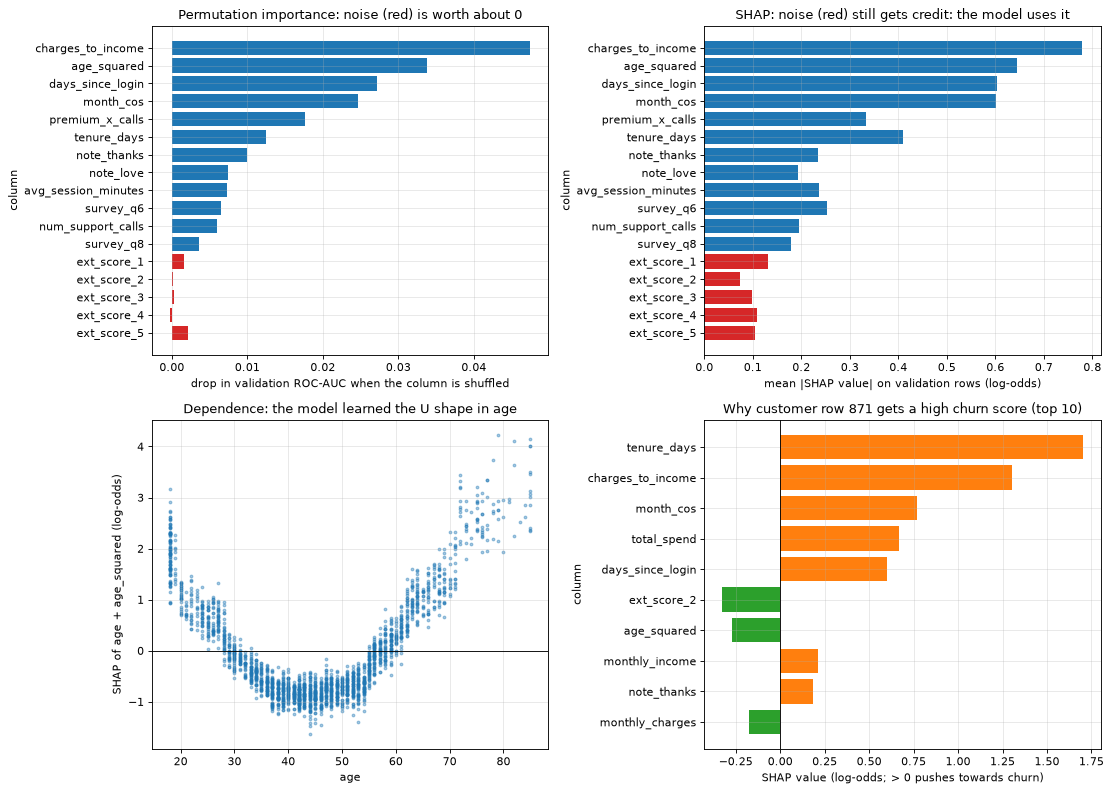

In [21]:
NOISE = [f"ext_score_{i}" for i in range(1, 6)]                  # Lab 17's pure-noise columns: known to be useless


def held_out_permutation(model, X, y, repeats=5):
    """Permutation importance on each fold's validation rows (rows the fitted model never saw), averaged over the
    5 folds: how much the validation ROC-AUC drops when one column's values are shuffled."""
    drops = []
    for fit_rows, val_rows in CV.split(X, y):
        fitted = model.fit(X.iloc[fit_rows], y.iloc[fit_rows])
        drops.append(permutation_importance(fitted, X.iloc[val_rows], y.iloc[val_rows], scoring="roc_auc",
                                            n_repeats=repeats, random_state=SEED).importances_mean)
    return pd.Series(np.mean(drops, axis=0), index=X.columns)


def held_out_shap(model, X, y):
    """SHAP value of every row and column (log-odds), each row explained by the fold model that did not see it."""
    values = np.zeros(X.shape)
    for fit_rows, val_rows in CV.split(X, y):
        fitted = model.fit(X.iloc[fit_rows], y.iloc[fit_rows])
        values[val_rows] = shap.TreeExplainer(fitted).shap_values(X.iloc[val_rows])
    return pd.DataFrame(values, index=X.index, columns=X.columns)


perm, shap_values = held_out_permutation(tree_model(), X_sel, y), held_out_shap(tree_model(), X_sel, y)
mean_shap = shap_values.abs().mean()
perm_rank, shap_rank = perm.rank(ascending=False).astype(int), mean_shap.rank(ascending=False).astype(int)
print(f"trees on X_sel ({X_sel.shape[1]} columns): CV ROC-AUC {cv_auc(tree_model(), X_sel, y):.3f}\n")
print(f"{'column':22s} {'permutation: AUC drop':>22s} {'mean |SHAP| (log-odds)':>24s}")
for column in list(perm.sort_values(ascending=False).index[:8]) + NOISE:
    print(f"{column:22s} {perm[column]:+14.4f} (#{perm_rank[column]:2d}) {mean_shap[column]:16.3f} (#{shap_rank[column]:2d})")

# One customer, explained by the model fitted on all training rows: base value + SHAP values = the model's log-odds
final = tree_model().fit(X_sel, y)
explainer = shap.TreeExplainer(final)
customer = final.predict_proba(X_sel)[:, 1].argsort()[-50]                  # <- try another row number
one = pd.Series(explainer.shap_values(X_sel.iloc[[customer]])[0], index=X_sel.columns)
base = float(np.ravel(explainer.expected_value)[0])
print(f"\ncustomer row {customer}: base {base:+.3f} + SHAP sum {one.sum():+.3f} = {base + one.sum():+.3f} log-odds; "
      f"model says {final.decision_function(X_sel.iloc[[customer]])[0]:+.3f} "
      f"(churn probability {final.predict_proba(X_sel.iloc[[customer]])[0, 1]:.2f}, actually churned: {y.iloc[customer]})")
print("biggest contributions:", one.reindex(one.abs().sort_values(ascending=False).index[:6]).round(2).to_dict())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
shown = list(perm.sort_values(ascending=False).index[:12]) + NOISE
colors = ["tab:red" if c in NOISE else "tab:blue" for c in shown]
axes[0, 0].barh(shown[::-1], perm[shown][::-1], color=colors[::-1])
axes[0, 0].set_xlabel("drop in validation ROC-AUC when the column is shuffled"); axes[0, 0].set_ylabel("column")
axes[0, 0].set_title("Permutation importance: noise (red) is worth about 0")
axes[0, 1].barh(shown[::-1], mean_shap[shown][::-1], color=colors[::-1])
axes[0, 1].set_xlabel("mean |SHAP value| on validation rows (log-odds)"); axes[0, 1].set_ylabel("column")
axes[0, 1].set_title("SHAP: noise (red) still gets credit: the model uses it")
known = X_sel["age"].notna()
axes[1, 0].scatter(X_sel.loc[known, "age"], (shap_values["age"] + shap_values["age_squared"])[known], s=6, alpha=0.4)
axes[1, 0].axhline(0, color="black", lw=0.8)
axes[1, 0].set_xlabel("age"); axes[1, 0].set_ylabel("SHAP of age + age_squared (log-odds)")
axes[1, 0].set_title("Dependence: the model learned the U shape in age")
top = one.reindex(one.abs().sort_values(ascending=False).index[:10])[::-1]
axes[1, 1].barh(top.index, top, color=["tab:orange" if v > 0 else "tab:green" for v in top])
axes[1, 1].axvline(0, color="black", lw=0.8)
axes[1, 1].set_xlabel("SHAP value (log-odds; > 0 pushes towards churn)"); axes[1, 1].set_ylabel("column")
axes[1, 1].set_title(f"Why customer row {customer} gets a high churn score (top 10)")
plt.tight_layout(); plt.show()

> **How to read this (importance on the engineered table)**
> * Both tools agree on the top four: `charges_to_income` (AUC drop **0.0475**, mean |SHAP| **0.779**), `age_squared`,
>   `days_since_login` and `month_cos`. All of the top five by permutation are columns **we built**: the ratio
>   (Lab 13), days since login and the cyclical month (Lab 12), age² and premium × calls (Lab 14). The raw `age` and
>   `monthly_income` they came from don't make the top 12 (top left). That answers "did my features help?": the model
>   leans on them.
> * **The noise columns (red) are where the two tools differ.** Shuffling them changes the validation AUC by
>   **−0.0003 to +0.0021**, at most 4 % of the top column, and one change is negative: chance level, i.e. useless.
>   Their mean |SHAP| is **0.074–0.131**, 10–17 % of the top column and clearly above 0 (top right). The trees do split
>   on noise, so SHAP, which reports what the model *uses*, gives it credit. Mean |SHAP| can never be negative, so it
>   can never say "useless". By rank alone the two look alike (noise sits at #15–#34 by permutation, #16–#28 by SHAP);
>   the sizes show the difference.
> * **Bottom left (dependence plot):** the SHAP values of `age` and `age_squared` added together are the model's whole
>   age effect for each customer. It is the U shape built into the data (Lab 0): about −1 log-odds between 35 and 55,
>   rising to +1 to +3 at 18 and +2 to +4 above 75. SHAP shows the *shape* of what the model learned, not just a size.
> * **Bottom right (one customer):** row 871 gets churn probability **0.99** (and did churn). Base **+0.058** plus the
>   contributions (sum **+5.220**) gives **+5.278** log-odds, exactly the model's output. The biggest pushes:
>   `tenure_days` **+1.70** (32 days: the newest customer in the table), `charges_to_income` **+1.30** (missing for
>   this customer, because income is missing, which Lab 6 showed is a churn signal), `month_cos` **+0.77**,
>   `total_spend` **+0.67**, `days_since_login` **+0.60**. The noise column `ext_score_2` contributes **−0.33**: SHAP
>   explains the model as it is, noise included.
> * **Which to use:** permutation importance on held-out rows to decide whether a column earns its place; SHAP to see
>   how the model uses it and to explain single predictions. Dropping columns because of either is still feature
>   selection, so it belongs inside the CV pipeline (Lab 17's leak applies).

with retention_call_made: CV ROC-AUC 0.977 (fake); top permutation importances:
retention_call_made    0.3007
charges_to_income      0.0077
age_squared            0.0047
days_since_login       0.0035



with a near-copy: CV ROC-AUC 0.855; importance as a share of the original's (alone = 1.00):
                   permutation  mean |SHAP|
charges_to_income         0.26         0.54
ratio_copy                0.18         0.49
sum of the two: {'permutation': 0.44, 'mean |SHAP|': 1.03}



random forest, 37 columns (1 = most important):
                   impurity rank  permutation rank
charges_to_income              1                 5
random_number                 13                33
note_thanks                   32                11
random_coin                   36                27


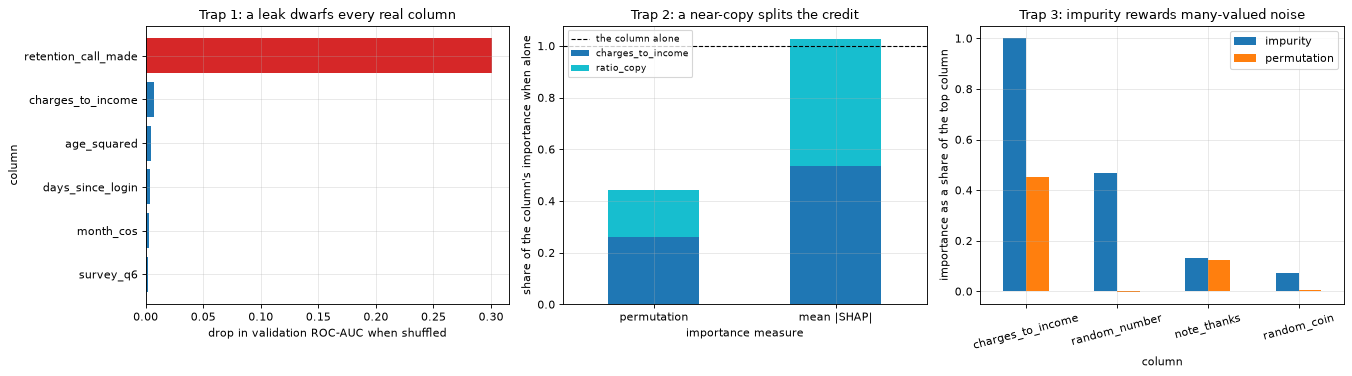

In [22]:
# Trap 1 - a leak lights up: put back Lab 4's leaky column
X_leak = X_sel.assign(retention_call_made=(train["retention_call_made"] == "yes").astype(int))
perm_leak = held_out_permutation(tree_model(), X_leak, y)
print(f"with retention_call_made: CV ROC-AUC {cv_auc(tree_model(), X_leak, y):.3f} (fake); top permutation importances:")
print(perm_leak.sort_values(ascending=False).head(4).round(4).to_string())

# Trap 2 - a near-copy splits the credit: add charges_to_income again, with 1 % noise
rng = np.random.default_rng(SEED)
X_copy = X_sel.assign(ratio_copy=X_sel["charges_to_income"] * (1 + rng.normal(0, 0.01, len(X_sel))))
perm_copy, shap_copy = held_out_permutation(tree_model(), X_copy, y), held_out_shap(tree_model(), X_copy, y)
share = pd.DataFrame({
    "permutation": [perm_copy["charges_to_income"], perm_copy["ratio_copy"]] / perm["charges_to_income"],
    "mean |SHAP|": [shap_copy["charges_to_income"].abs().mean(), shap_copy["ratio_copy"].abs().mean()]
                   / mean_shap["charges_to_income"]}, index=["charges_to_income", "ratio_copy"])
print(f"\nwith a near-copy: CV ROC-AUC {cv_auc(tree_model(), X_copy, y):.3f}; importance as a share of the original's (alone = 1.00):")
print(share.round(2).to_string())
print("sum of the two:", share.sum().round(2).to_dict())

# Trap 3 - impurity importance favours columns with many distinct values: add two pure-noise columns
X_noisy = X_sel.assign(random_number=rng.normal(size=len(X_sel)), random_coin=rng.integers(0, 2, len(X_sel)))
forest = make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))
impurity = pd.Series(forest.fit(X_noisy, y)[-1].feature_importances_, index=X_noisy.columns)
perm_forest = held_out_permutation(forest, X_noisy, y, repeats=3)
compare = ["charges_to_income", "random_number", "note_thanks", "random_coin"]
ranks = pd.DataFrame({"impurity rank": impurity.rank(ascending=False).astype(int)[compare],
                      "permutation rank": perm_forest.rank(ascending=False).astype(int)[compare]})
print(f"\nrandom forest, {X_noisy.shape[1]} columns (1 = most important):")
print(ranks.to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
top_leak = perm_leak.sort_values(ascending=False).head(6)[::-1]
axes[0].barh(top_leak.index, top_leak, color=["tab:red" if c == "retention_call_made" else "tab:blue" for c in top_leak.index])
axes[0].set_xlabel("drop in validation ROC-AUC when shuffled"); axes[0].set_ylabel("column")
axes[0].set_title("Trap 1: a leak dwarfs every real column")
share.T.plot.bar(stacked=True, ax=axes[1], rot=0, color=["tab:blue", "tab:cyan"])
axes[1].axhline(1, color="black", ls="--", lw=1, label="the column alone")
axes[1].set_xlabel("importance measure"); axes[1].set_ylabel("share of the column's importance when alone")
axes[1].set_title("Trap 2: a near-copy splits the credit"); axes[1].legend(fontsize=8, loc="upper left")
normalised = pd.DataFrame({"impurity": impurity[compare] / impurity.max(),
                           "permutation": perm_forest[compare] / perm_forest.max()})
normalised.plot.bar(ax=axes[2], rot=15)
axes[2].set_xlabel("column"); axes[2].set_ylabel("importance as a share of the top column")
axes[2].set_title("Trap 3: impurity rewards many-valued noise")
plt.tight_layout(); plt.show()

> **How to read this (three traps)**
> * **Trap 1, a leak lights up (left):** with Lab 4's `retention_call_made` put back, the CV ROC-AUC jumps to
>   **0.977** (fake) and shuffling that one column costs **0.301** AUC, 39 times the next column. `charges_to_income`
>   drops from **0.0475** to **0.0077**: the model hardly needs the real columns any more. One column towering over
>   the rest is the signature of a leak, so look at an importance chart whenever a score seems too good.
> * **Trap 2, a near-copy splits the credit (middle):** adding `ratio_copy` (`charges_to_income` with 1 % noise)
>   leaves the score unchanged (**0.855** vs **0.856**). Permutation importance now gives the original **0.26** and the
>   copy **0.18** of what the original had alone, **0.44** together: when one is shuffled the model still has the
>   other, so both look minor. SHAP gives **0.54** and **0.49**, **1.03** together: it splits the credit but keeps the
>   total. With correlated columns (Lab 16), judge them as a group, or drop near-copies before reading importances.
> * **Trap 3, impurity importance (right):** a random forest's built-in `feature_importances_` adds up how much each
>   column's splits purify the **training** rows. It ranks `random_number` (pure noise, every value different) **#13
>   of 37**, far above the real effect `note_thanks` (**#32**). Permutation importance on held-out rows puts them at
>   **#33** and **#11**. A column with many distinct values offers many split points, so on training rows it always
>   finds some split that helps by chance; the 0/1 `random_coin` offers only one, and impurity ranks it **#36**.
>   XGBoost's and LightGBM's built-in importances (gain or split counts) are also computed from training-time splits
>   and share the bias; scikit-learn's `HistGradientBoostingClassifier` doesn't offer one at all.
> * **Lesson:** measure importance on rows the model didn't train on, read correlated columns together, and treat a
>   towering column as a leak until proven otherwise.

---
<a id="part-f"></a>
# Part F — Putting it together

<a id="lab-20"></a>
## Lab 20 · Validate every step by cross-validation: the pipeline scripts

**Goal:** run all the steps as one pipeline — the scripts in [`../scripts/`](../scripts/README.md), controlled by
`config.yml` — then switch each step off in turn and measure what it was worth. Finally, and only now, score the
test rows from Lab 1, once.

Inside the runner, each of the 5 cross-validation folds re-fits **every** step on that fold's training rows only
(medians, caps, category rates, chosen columns, PCA directions, ...) and scores the fold's validation rows.
That is the only way the CV score stays honest when the pipeline learns things from data.

In [23]:
sys.path.insert(0, str(SCRIPTS_DIR.resolve()))
import run_pipeline                                                     # ../scripts/run_pipeline.py

config = run_pipeline.read_config(SCRIPTS_DIR / "config.yml")
full_run = run_pipeline.run_pipeline(config, SCRIPTS_DIR.resolve())     # prints every stage and the scores

Stages (top to bottom):
  [on ] load_data                (required) 3000 rows x 35 columns
  [on ] split_data               (required) train 2400 / test 600, 5 CV folds on train
  [on ] drop_useless_columns     dropped 3: customer_id (id-like (almost every value is different)), country (constant), monthly_fee (duplicate of monthly_charges)
  [on ] remove_leakage           dropped retention_call_made (AUC 0.93 on its own); suspicious columns still present: none
  [on ] fix_data_types           money -> float: ['monthly_charges']; yes/no -> 0/1: ['is_senior']; tidied spellings: payment_method 13->4 values; impossible values -> missing: ['age']
  [on ] make_date_features       from ['signup_date', 'last_login_date'] made ['signup_date_days_since', 'signup_date_month_sin', 'signup_date_month_cos', 'last_login_date_days_since', 'last_login_date_month_sin', 'last_login_date_month_cos']
  [on ] make_domain_features     made ['charges_to_income', 'active_lifetime_days', 'income_vs_city_median'

> **How to read this**
> * Each line is one stage, in order, with what it learned on the training rows: the 3 useless columns, the leak,
>   13 spellings → 4, the date features, the flags, the caps, the un-skewed columns, 119 cities → 16 (then
>   target-encoded), the near-copies dropped, 8 survey columns → 1 PCA column, and the columns the lasso kept.
> * Final score: CV ROC-AUC **0.895** ± 0.011 on the training rows and **0.893** on the 600 test rows,
>   used for the first time. The two agree, which is what an honest CV estimate should do.

run                                     CV ROC-AUC   change  test ROC-AUC
(all enabled stages)                  0.895 ± 0.011   +0.000         0.893
without drop_useless_columns          0.895 ± 0.011   +0.000         0.893
without remove_leakage                0.984 ± 0.003   +0.089         0.989
without fix_data_types                0.892 ± 0.011   -0.003         0.890
without make_date_features            0.872 ± 0.008   -0.023         0.864
without make_domain_features          0.896 ± 0.010   +0.001         0.896
without impute_missing                0.881 ± 0.012   -0.014         0.881
without cap_outliers                  0.897 ± 0.010   +0.002         0.893
without transform_skewed              0.895 ± 0.011   -0.000         0.896
without group_rare_categories         0.890 ± 0.010   -0.005         0.883
without encode_categoricals           0.875 ± 0.005   -0.020         0.869
without add_interactions              0.889 ± 0.007   -0.006         0.888
without bin_numeric       

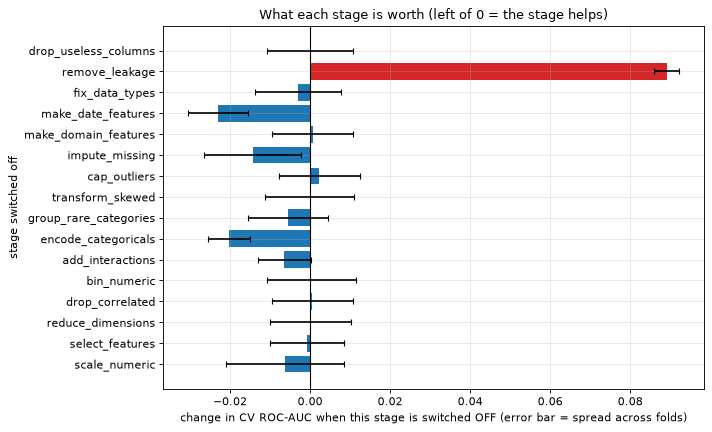

In [24]:
ablation = run_pipeline.run_ablation(config, SCRIPTS_DIR.resolve())     # one run per stage switched off (~20 s)
run_pipeline.print_ablation(ablation)

labels = [label.replace("without ", "") for label, _ in ablation[1:]]
change = np.array([s["cv"]["roc_auc"]["mean"] for _, s in ablation[1:]]) - ablation[0][1]["cv"]["roc_auc"]["mean"]
spread = np.array([s["cv"]["roc_auc"]["std"] for _, s in ablation[1:]])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(labels, change, xerr=spread, color=["tab:red" if c > 0.02 else "tab:blue" for c in change], capsize=3)
ax.axvline(0, color="black", lw=1)
ax.invert_yaxis()
ax.set_xlabel("change in CV ROC-AUC when this stage is switched OFF (error bar = spread across folds)")
ax.set_ylabel("stage switched off")
ax.set_title("What each stage is worth (left of 0 = the stage helps)")
plt.tight_layout(); plt.show()

> **How to read this**
> * Bars to the **left** of zero: the score drops without that stage, so the stage helps. The big ones are date
>   features (**−0.023**), encoding the categories (**−0.020**) and imputation with flags (**−0.014**), then
>   interactions, scaling and rare-category grouping (−0.005 to −0.006).
> * Bars near zero (inside the error bars): the stage changes nothing *in this pipeline* — dropping useless columns,
>   domain features, capping, un-skewing, binning, dropping correlated columns, PCA, feature selection.
>   That does not mean the step is useless in general: often a later stage covers for it (with
>   `drop_useless_columns` off, the ID is still turned into one meaningless "other" category by rare-category
>   grouping). Keep a step if it protects you (IDs, typos) even when today's score doesn't need it.
> * The **red** bar: switching off `remove_leakage` "improves" the score to **0.984**. A leak always looks like
>   the best feature you ever made. CV cannot catch it — only the question *"would I know this at prediction time?"*.
> * Differences smaller than the error bars (±0.01) are noise. Before believing a gain, check that it is bigger than
>   the spread across folds.
> * Comparing 17 runs on the same CV folds and keeping the best is itself a mild form of fitting to the validation
>   rows. That is why the test rows are scored **once**, at the very end, after all choices are made.

                        no feature engineering  all stages  test (all stages)
logistic_regression                      0.727       0.895              0.893
knn                                      0.638       0.850              0.861
random_forest                            0.773       0.868              0.871
hist_gradient_boosting                   0.771       0.871              0.882


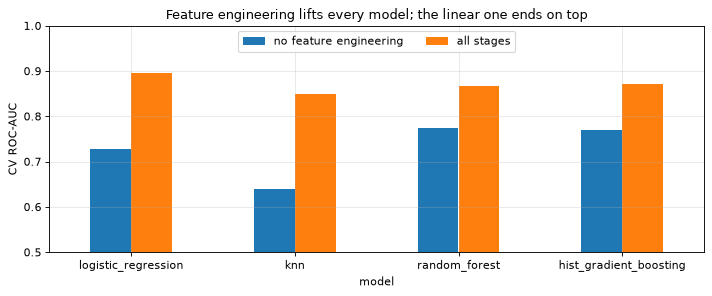

In [25]:
import copy

optional = [s["name"] for s in config["stages"] if not s.get("required")]
comparison = {}
for model in ["logistic_regression", "knn", "random_forest", "hist_gradient_boosting"]:
    model_config = copy.deepcopy(config)
    model_config["stages"][-1]["params"]["model"] = model
    bare = run_pipeline.run_pipeline(run_pipeline.switch_off(model_config, optional), SCRIPTS_DIR.resolve(), verbose=False)
    full = run_pipeline.run_pipeline(model_config, SCRIPTS_DIR.resolve(), verbose=False)
    comparison[model] = {"no feature engineering": bare["cv"]["roc_auc"]["mean"],
                         "all stages": full["cv"]["roc_auc"]["mean"],
                         "test (all stages)": full["test"]["roc_auc"]}
comparison = pd.DataFrame(comparison).T
print(comparison.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3.8))
comparison[["no feature engineering", "all stages"]].plot.bar(ax=ax, rot=0)
ax.set_ylim(0.5, 1.0); ax.set_xlabel("model"); ax.set_ylabel("CV ROC-AUC")
ax.set_title("Feature engineering lifts every model; the linear one ends on top"); ax.legend(loc="upper center", ncols=2)
plt.tight_layout(); plt.show()

> **How to read this**
> * "No feature engineering" = only the required stages: the model gets whatever numeric columns the raw table
>   happens to have (text dropped, gaps filled with 0).
> * Every model gains: logistic regression **0.727 → 0.895**, k-NN **0.638 → 0.850**, random forest
>   **0.773 → 0.868**, gradient boosting **0.771 → 0.871**. The test scores (0.861–0.893) agree with CV.
> * The order of models **flips**: without feature engineering the tree models win; with it, plain logistic
>   regression wins. Good features beat a fancier model, and a linear model that is given the right shapes (logs,
>   squares, interactions, cyclical months) is hard to beat on tabular data.
> * To repeat this yourself from a terminal, see [`../scripts/README.md`](../scripts/README.md): toggle
>   `enabled: false` in `config.yml` (or pass `--disable stage_name`) and re-run.

---
<a id="summary"></a>
# Summary — what each lab showed

| Lab | Step | Claim from the README | Verdict (CV ROC-AUC unless stated) |
|---|---|---|---|
| 0 | Meet the data | Look before you touch | 3,000 rows, 35 columns, churn share 0.5; mess visible in 3 rows |
| 1 | Split first | Stratify; lock the test part away | stratified test share always 0.475 vs 0.300–0.700 random (200-row sample) |
| 2 | Column types | The kind of a column decides the steps | money, dates, yes/no stored as text; an ID; a constant; free text |
| 3 | Useless columns | IDs can only be memorised | tree on ID: 1.000 on its own rows, 0.518 on new rows |
| 4 | Leakage | Too good to be true = leak | one column 0.936 alone; model 0.702 → 0.960 with it (fake) |
| 5 | Data types | Let the model read the data | 13 spellings → 4; 0.702 → 0.776 |
| 6 | Missing values | Flags carry signal when missingness does | median 0.745 → + flags 0.778; age flag adds nothing |
| 7 | Outliers | Cap distorting extremes; trees don't care | weight of calls 0.053 → 0.214; ✘ fraud toy 0.999 → 0.981 |
| 8 | Skew | log helps linear models, not trees | 0.745 → 0.759; trees identical; ✘ accelerating toy 0.878 → 0.870 |
| 9 | Scaling | Matters for distances, not trees | k-NN 0.617 → 0.730; trees 0.798 everywhere |
| 10 | Encoding | Target encoding only cross-fitted | naive 0.800 (fake); noise column 0.822 naive vs 0.498 honest |
| 11 | Rare categories | Group the tiny ones, not everything | 119 columns 0.746 → 16 columns 0.768; ✘ 3 columns 0.766 |
| 12 | Dates | Days-since + cyclical month | 0.745 → 0.771 → 0.803 with sin / cos; month as 1..12 adds nothing |
| 13 | Domain features | Each idea must earn its place | keywords 0.822 → 0.842; ratio +0.005; aggregate / difference nothing |
| 14 | Interactions | Give linear models U shapes and "it depends" | 0.845 → 0.879; ✘ all 435 products 0.830 |
| 15 | Binning | Flexible shapes, at the cost of detail | age 0.854 → 0.874 (10 bins); ✘ smooth toy 0.871 → 0.856; trees 0.855 → 0.844 |
| 16 | Correlated columns | Hurts stability, not score | weight spread 0.345 → 0.069; score 0.879 both |
| 17 | Feature selection | Select inside CV, or it lies | lasso 24 of 35 columns at 0.879; ✘ noise: 0.760 selected outside CV vs 0.450 inside |
| 18 | Dimensionality reduction | Compress groups; LDA when labels exist | 8 survey columns → 1 at 0.879; cancer PCA 0.971 vs LDA 0.993 |
| 19 | Feature importance | Judge usefulness on held-out rows; SHAP shows use | top 5 by permutation all engineered; noise ≈ 0 by permutation, 10–17 % of the top by SHAP; ✘ leak towers (0.301); a copy halves SHAP credit; impurity ranks noise #13 of 37 |
| 20 | Validate every step | Ablation by CV, test once | full 0.895 CV / 0.893 test; bare 0.727; leak "+0.089" |